# 04 — Фьючерсная кривая WTI и календарный спрэд

Цель: описать уровень и форму фьючерсной кривой WTI (2015–2026), разобраться с роллами в
nearby-рядах Barchart и решить, как правильно считать дневные изменения спрэда; сверить Barchart с
EIA; посмотреть связь спрэда с запасами и проверить ключевой вопрос проекта — двигает ли
inventory surprise календарный спрэд F1−F2 в день релиза EIA.

Файлы (`eda/data/processed/`):
- `market/barchart_wti_curve_2015_onward.parquet` — дневная кривая F1–F6, F12 (close), спрэды и их `delta_*`;
- `market/barchart_wti_nearbys_2015_onward.parquet` — OHLC, `chart_volume_like_main`, `open_interest` по каждому nearby;
- `market/barchart_wti_download_metadata.parquet` — метаданные выгрузки;
- `eia/eia_wti_futures_features_2015_2024.parquet` — F1–F4 EIA (RCLC1–4) для сверки;
- `eia/eia_weekly_features.parquet` — запасы Cushing и коммерческие запасы;
- `u.release_frame()` — релизы EIA, консенсус, surprise, API.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

import eda_utils as u

u.setup_style()

curve_raw = u.load("market/barchart_wti_curve_2015_onward.parquet")
nearbys = u.load("market/barchart_wti_nearbys_2015_onward.parquet")
meta = u.load("market/barchart_wti_download_metadata.parquet")
eia_fut = u.load("eia/eia_wti_futures_features_2015_2024.parquet")
weekly = u.load("eia/eia_weekly_features.parquet")
releases = u.release_frame()

# Nullable Float64 -> float64, дата в индекс
bc = curve_raw.set_index("trading_day").sort_index()
num_cols = bc.select_dtypes("number").columns
bc[num_cols] = bc[num_cols].astype("float64")
days = bc.index
pos = pd.Series(np.arange(len(days)), index=days)
eia = eia_fut.set_index("period").sort_index()
EIA_START, EIA_END = eia.index.min(), eia.index.max()


def rnd(df, n=3):
    """Округлить только числовые колонки."""
    if isinstance(df, pd.Series):
        return df.round(n)
    out = df.copy()
    cols = out.select_dtypes("number").columns
    out[cols] = out[cols].round(n)
    return out


def ols(y, x, cov="HC1"):
    """МНК y ~ const + x с робастными (HC1) ошибками; x — Series или DataFrame."""
    X = sm.add_constant(pd.DataFrame(x).astype(float))
    d = pd.concat([pd.Series(y, name="__y"), X], axis=1).dropna()
    return sm.OLS(d["__y"], d.drop(columns="__y")).fit(cov_type=cov)


print("Barchart кривая:", bc.shape, days.min().date(), "→", days.max().date())
print("Barchart nearbys:", nearbys.shape, "| EIA фьючерсы:", eia.shape, EIA_START.date(), "→", EIA_END.date())
print("EIA weekly:", weekly.shape, "| релизы:", releases.shape)
print(bc[["source", "roll_method", "price_field"]].drop_duplicates().to_string())

Barchart кривая: (2981, 26) 2015-01-02 → 2026-11-05
Barchart nearbys: (20867, 14) | EIA фьючерсы: (2305, 10) 2015-02-19 → 2024-04-05
EIA weekly: (610, 39) | релизы: (616, 7)
                                         source                           roll_method price_field
trading_day                                                                                      
2015-01-02   barchart_premier_interactive_chart  barchart_daily_nearby_liquidity_roll       close


## 1. Данные и их качество

Проверяем календарь торговых дней (пропуски, дубликаты, выходные), семантику объёма и open interest,
смысл колонки `change` и метаданные выгрузки.

In [2]:
from pandas.tseries.holiday import GoodFriday, USFederalHolidayCalendar

dup_days = days.duplicated().sum()
weekend_rows = (days.day_of_week >= 5).sum()
bdays = pd.bdate_range(days.min(), days.max())
missing_wd = bdays.difference(days)
fed = USFederalHolidayCalendar().holidays(days.min(), days.max(), return_name=True)
good_fri = pd.DatetimeIndex(
    [GoodFriday.dates(f"{y}-01-01", f"{y}-12-31")[0] for y in range(days.min().year, days.max().year + 1)]
)
miss_names = pd.Series(
    [fed.get(d, "Good Friday" if d in good_fri else "НЕ ПРАЗДНИК") for d in missing_wd], index=missing_wd
)
print(f"дубликаты дат: {dup_days}, строки в выходные: {weekend_rows}")
print(f"будни без котировок: {len(missing_wd)}; из них не праздники: {(miss_names == 'НЕ ПРАЗДНИК').sum()}")
print(miss_names.value_counts().to_string())
present_hol = pd.Series({d.date(): fed[d] for d in days if d in fed.index})
print("\nфедеральные праздники, в которые есть торги (CME открыта):")
print(present_hol.value_counts().to_string())
print("\nстрок по годам:", pd.Series(days.year).value_counts().sort_index().to_dict())

дубликаты дат: 0, строки в выходные: 0
будни без котировок: 109; из них не праздники: 0
Birthday of Martin Luther King, Jr.     12
Washington's Birthday                   12
Good Friday                             12
Memorial Day                            12
Independence Day                        12
Labor Day                               12
Thanksgiving Day                        11
Christmas Day                           11
New Year's Day                          10
Juneteenth National Independence Day     5

федеральные праздники, в которые есть торги (CME открыта):
Columbus Day                            12
Veterans Day                            11
Juneteenth National Independence Day     1
New Year's Day                           1

строк по годам: {2015: 252, 2016: 252, 2017: 251, 2018: 252, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 251, 2026: 213}


In [3]:
nb = nearbys.sort_values(["nearby", "trading_day"]).copy()
for col in ["open", "high", "low", "close", "change", "chart_volume_like_main", "open_interest"]:
    nb[col] = nb[col].astype("float64")
nb["dclose"] = nb.groupby("nearby")["close"].diff()
vol_wide = nb.pivot(index="trading_day", columns="nearby", values="chart_volume_like_main")
qa = pd.DataFrame(
    {
        "строк": nb.groupby("nearby").size(),
        "OI заполнен": nb.groupby("nearby")["open_interest"].apply(lambda s: s.notna().sum()),
        "change ≠ diff(close)": nb.groupby("nearby").apply(
            lambda g: ((g["change"] - g["dclose"]).abs() > 0.005).sum(), include_groups=False
        ),
        "high<low": nb.groupby("nearby").apply(lambda g: (g["high"] < g["low"]).sum(), include_groups=False),
        "close вне [low, high]": nb.groupby("nearby").apply(
            lambda g: ((g["close"] > g["high"] + 1e-9) | (g["close"] < g["low"] - 1e-9)).sum(),
            include_groups=False,
        ),
        "close ≤ 0": nb.groupby("nearby")["close"].apply(lambda s: (s <= 0).sum()),
    }
)
print(qa.to_string())
same_vol = (vol_wide.nunique(axis=1) == 1).mean()
print(f"\nдоля дней, где объём одинаков во всех 7 nearby: {same_vol:.3f}")
print("объём (млн контрактов/день):", (vol_wide[1].describe()[["min", "50%", "max"]] / 1e6).round(2).to_dict())
print(meta[["nearby", "downloaded_at", "download_timezone", "raw_first_day", "raw_rows", "model_rows",
            "open_interest_available"]].to_string(index=False))

        строк  OI заполнен  change ≠ diff(close)  high<low  close вне [low, high]  close ≤ 0
nearby                                                                                      
1        2981            0                     0         0                      0          0
2        2981            0                     0         0                      0          0
3        2981            0                     0         0                      0          0
4        2981            0                     0         0                      0          0
5        2981            0                     0         0                      0          0
6        2981            0                     0         0                      0          0
12       2981            0                     0         0                      0          0

доля дней, где объём одинаков во всех 7 nearby: 1.000
объём (млн контрактов/день): {'min': 0.26, '50%': 0.94, 'max': 4.14}
 nearby       downloaded_at download_ti

**Вывод.** Календарь Barchart чистый: 2981 торговый день, 0 дубликатов, 0 строк в выходные; все 109 пропущенных
будней — биржевые праздники CME (MLK, Presidents Day, Good Friday, Memorial, July 4, Labor, Thanksgiving, Christmas,
New Year, Juneteenth с 2022), а Columbus/Veterans Day — торговые дни и присутствуют. OHLC консистентны, цен ≤ 0 нет.
Но: `open_interest` пуст во всех 20 867 строках; `chart_volume_like_main` одинаков во всех 7 nearby в 100% дней
(медиана 0,94 млн контрактов/день) — это не объём конкретного контракта, использовать как признак ликвидности
месяца нельзя (что именно он суммирует, по данным не проверить); `change` = diff(close) nearby-ряда, т.е. в день ролла
он тоже смешивает контракты. Сырые файлы начинаются с 2000-01-04 (6743 строки), в processed — только с 2015.

## 2. Уровень и форма кривой

Соглашение проекта: спрэд = F_near − F_far; > 0 — бэквордация, < 0 — контанго.

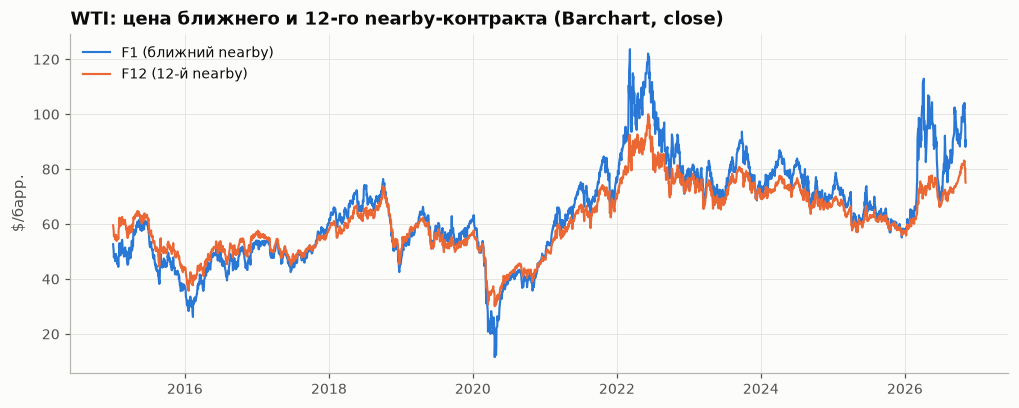

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(days, bc["wti_f1"], label="F1 (ближний nearby)", color=u.SERIES[0])
ax.plot(days, bc["wti_f12"], label="F12 (12-й nearby)", color=u.SERIES[1])
ax.set_title("WTI: цена ближнего и 12-го nearby-контракта (Barchart, close)")
ax.set_ylabel("$/барр.")
ax.legend(loc="upper left")
plt.show()

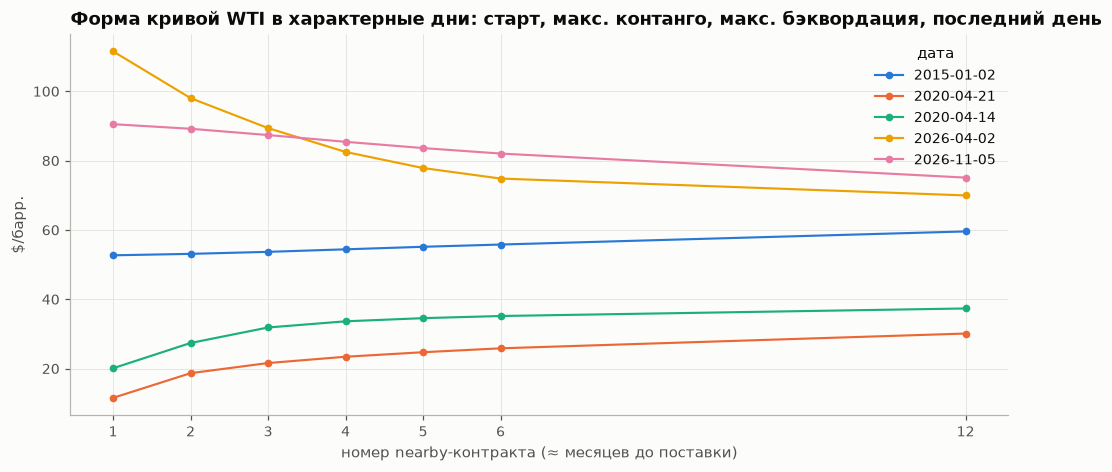

             wti_f1  wti_f2  wti_f3  wti_f4  wti_f5  wti_f6  wti_f12  spread_f1_f2  spread_f1_f12
trading_day                                                                                      
2015-01-02    52.69   53.11   53.69   54.42   55.15   55.80    59.58         -0.42          -6.89
2020-04-21    11.57   18.69   21.61   23.43   24.73   25.86    30.12         -7.12         -18.55
2020-04-14    20.11   27.40   31.87   33.65   34.56   35.18    37.36         -7.29         -17.25
2026-04-02   111.54   98.04   89.39   82.51   77.87   74.84    69.97         13.50          41.57
2026-11-05    90.52   89.20   87.39   85.44   83.63   82.05    75.11          1.32          15.41


In [5]:
snap_dates = [
    days[0],
    bc["spread_f1_f12"].idxmin(),
    bc["spread_f1_f2"].idxmin(),
    bc["spread_f1_f12"].idxmax(),
    days[-1],
]
snap_dates = list(dict.fromkeys(snap_dates))
mats = [1, 2, 3, 4, 5, 6, 12]
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, d in enumerate(snap_dates):
    ax.plot(mats, bc.loc[d, [f"wti_f{m}" for m in mats]].values, marker="o", color=u.SERIES[i], label=d.date())
ax.set_xticks(mats)
ax.set_xlabel("номер nearby-контракта (≈ месяцев до поставки)")
ax.set_ylabel("$/барр.")
ax.set_title("Форма кривой WTI в характерные дни: старт, макс. контанго, макс. бэквордация, последний день")
ax.legend(title="дата", ncols=1, loc="upper right")
plt.show()
print(rnd(bc.loc[snap_dates, [f"wti_f{m}" for m in mats] + ["spread_f1_f2", "spread_f1_f12"]], 2).to_string())

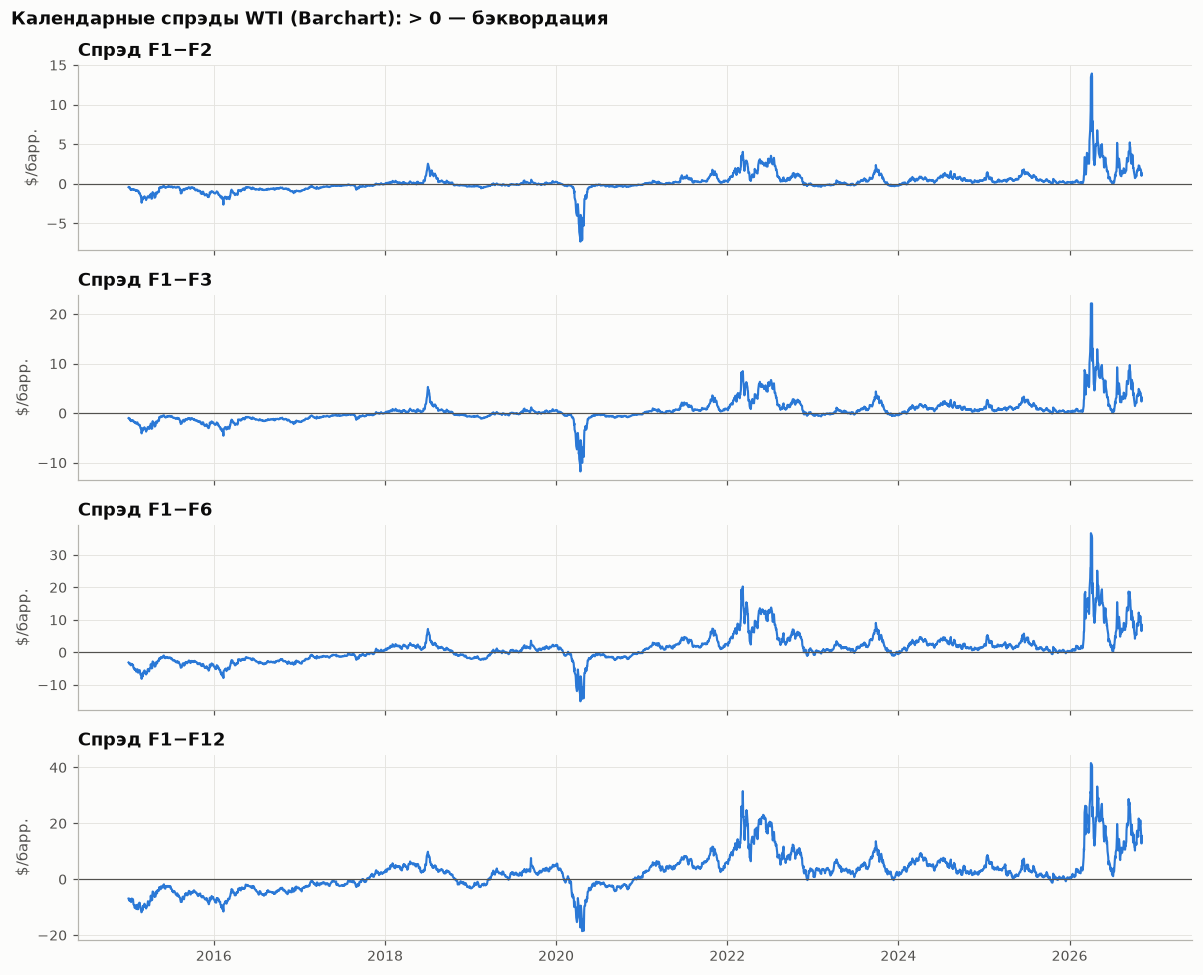

In [6]:
SPREADS = {"spread_f1_f2": "F1−F2", "spread_f1_f3": "F1−F3", "spread_f1_f6": "F1−F6", "spread_f1_f12": "F1−F12"}
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, (col, name) in zip(axes, SPREADS.items()):
    ax.plot(days, bc[col], color=u.SERIES[0])
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_title(f"Спрэд {name}")
    ax.set_ylabel("$/барр.")
fig.suptitle("Календарные спрэды WTI (Barchart): > 0 — бэквордация", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

Доля дней в бэквордации (спрэд > 0):
             F1−F2  F1−F3  F1−F6  F1−F12  дней
trading_day                                   
2015          0.00   0.00   0.00    0.00   252
2016          0.00   0.00   0.00    0.00   252
2017          0.02   0.04   0.12    0.22   251
2018          0.76   0.79   0.79    0.83   252
2019          0.32   0.44   0.68    0.78   252
2020          0.05   0.07   0.09    0.20   253
2021          0.91   0.98   1.00    1.00   252
2022          0.91   0.92   0.97    1.00   251
2023          0.51   0.58   0.88    1.00   250
2024          0.94   0.94   0.98    1.00   252
2025          1.00   0.99   0.95    0.93   251
2026          1.00   1.00   1.00    1.00   213
Всего         0.53   0.56   0.62    0.66  2981

Доля дней с нулевым спрэдом (плоская кривая), максимум по годам: {'F1−F2': 0.012, 'F1−F3': 0.012, 'F1−F6': 0.004, 'F1−F12': 0.004}


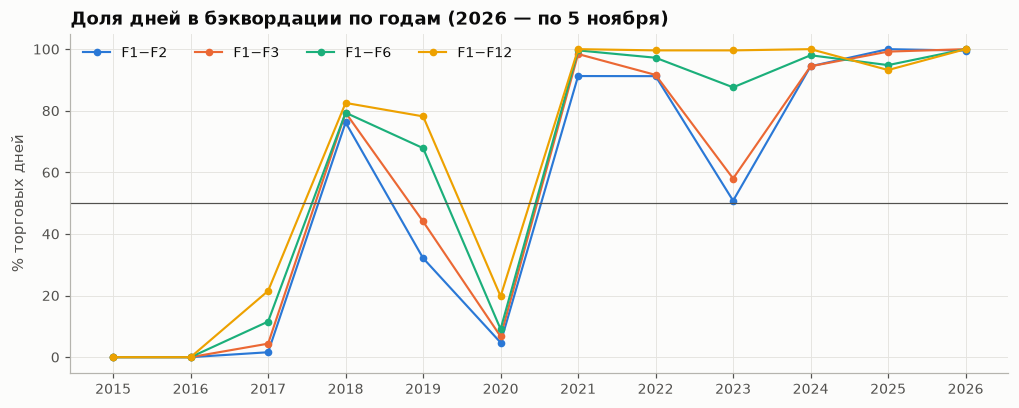

In [7]:
yr = days.year
back_share = pd.DataFrame({name: (bc[col] > 0).groupby(yr).mean() for col, name in SPREADS.items()})
flat_share = pd.DataFrame({name: (bc[col] == 0).groupby(yr).mean() for col, name in SPREADS.items()})
tbl = back_share.copy()
tbl.loc["Всего"] = [(bc[c] > 0).mean() for c in SPREADS]
tbl["дней"] = list(pd.Series(yr).value_counts().sort_index()) + [len(bc)]
print("Доля дней в бэквордации (спрэд > 0):")
print(rnd(tbl, 2).to_string())
print("\nДоля дней с нулевым спрэдом (плоская кривая), максимум по годам:", rnd(flat_share.max(), 3).to_dict())

fig, ax = plt.subplots(figsize=(11, 4))
for i, name in enumerate(back_share.columns):
    ax.plot(back_share.index, back_share[name] * 100, marker="o", color=u.SERIES[i], label=name)
ax.axhline(50, color=u.INK_MUTED, lw=0.8)
ax.set_xticks(back_share.index)
ax.set_ylabel("% торговых дней")
ax.set_title("Доля дней в бэквордации по годам (2026 — по 5 ноября)")
ax.legend(ncols=4, loc="upper left")
plt.show()

### Апрель 2020: отрицательная цена

20.04.2020 майский контракт CLK20 рассчитался по −37,63 $ за день до экспирации. Смотрим, как это
выглядит в Barchart и в EIA.

            BC F1  BC F2  BC F1−F2  EIA F1  EIA F2  EIA F3  EIA F1−F2
2020-04-13  22.41  29.26     -6.85   22.41   29.26   32.96      -6.85
2020-04-14  20.11  27.40     -7.29   20.11   27.40   31.87      -7.29
2020-04-15  26.04  29.96     -3.92   19.87   26.04   29.96      -6.17
2020-04-16  25.53  29.55     -4.02   19.87   25.53   29.55      -5.66
2020-04-17  25.03  29.42     -4.39   18.27   25.03   29.42      -6.76
2020-04-20  20.43  26.28     -5.85  -37.63   20.43   26.28     -58.06
2020-04-21  11.57  18.69     -7.12   10.01   11.57   18.69      -1.56
2020-04-22  13.78  20.69     -6.91   13.78   20.69   23.76      -6.91
2020-04-23  16.50  21.44     -4.94   16.50   21.44   24.12      -4.94
2020-04-24  16.94  21.22     -4.28   16.94   21.22   23.86      -4.28

min Barchart F1 за весь период: 11.57 (2020-04-21); min EIA F1: -37.63 (2020-04-20)
min Barchart F1−F2: -7.29 (2020-04-14); min EIA F1−F2: -58.06 (2020-04-20)
дней с F1 ≤ 0: Barchart 0 | EIA 1


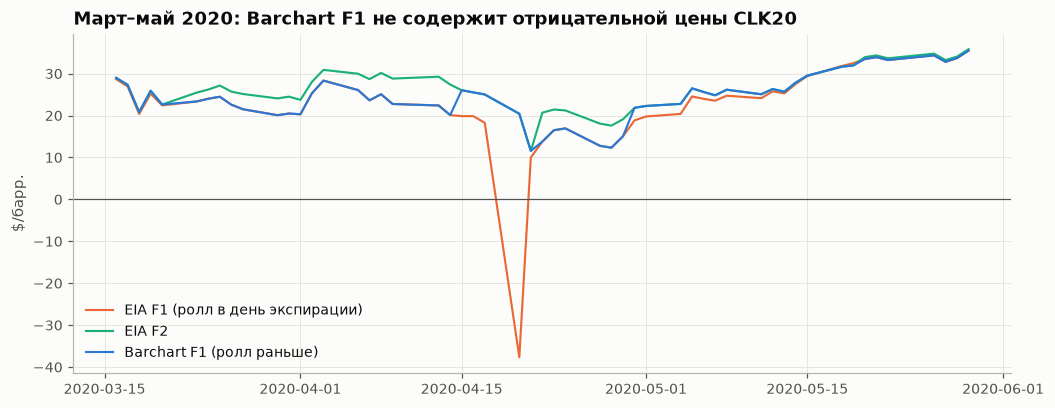

In [8]:
apr = pd.DataFrame(
    {
        "BC F1": bc["wti_f1"], "BC F2": bc["wti_f2"], "BC F1−F2": bc["spread_f1_f2"],
        "EIA F1": eia["wti_f1"], "EIA F2": eia["wti_f2"], "EIA F3": eia["wti_f3"], "EIA F1−F2": eia["spread_1_2"],
    }
).loc["2020-04-13":"2020-04-24"]
print(apr.to_string())
print(f"\nmin Barchart F1 за весь период: {bc['wti_f1'].min():.2f} ({bc['wti_f1'].idxmin().date()}); "
      f"min EIA F1: {eia['wti_f1'].min():.2f} ({eia['wti_f1'].idxmin().date()})")
print(f"min Barchart F1−F2: {bc['spread_f1_f2'].min():.2f} ({bc['spread_f1_f2'].idxmin().date()}); "
      f"min EIA F1−F2: {eia['spread_1_2'].min():.2f} ({eia['spread_1_2'].idxmin().date()})")
print("дней с F1 ≤ 0: Barchart", int((bc["wti_f1"] <= 0).sum()), "| EIA", int((eia["wti_f1"] <= 0).sum()))

win = slice("2020-03-16", "2020-05-29")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(eia.loc[win].index, eia.loc[win, "wti_f1"], color=u.SERIES[1], label="EIA F1 (ролл в день экспирации)")
ax.plot(eia.loc[win].index, eia.loc[win, "wti_f2"], color=u.SERIES[2], label="EIA F2")
ax.plot(bc.loc[win].index, bc.loc[win, "wti_f1"], color=u.SERIES[0], label="Barchart F1 (ролл раньше)")
ax.axhline(0, color=u.INK_MUTED, lw=0.8)
ax.set_ylabel("$/барр.")
ax.set_title("Март–май 2020: Barchart F1 не содержит отрицательной цены CLK20")
ax.legend(loc="lower left")
plt.show()

**Вывод.** Режимы кривой резко сменяются: 2015–2016 — 0% дней в бэквордации по всем четырём спрэдам; 2018 — 76% дней
в бэквордации (F1−F2); 2019 — 32%; 2020 — 5% (суперконтанго); 2021–2022 — 91%; 2023 — 51%; 2024 — 94%;
2025–2026 — ≈100%. За весь период F1−F2 > 0 в 53% дней, F1−F12 — в 66% (длинный конец чаще в бэквордации).
Экстремумы: F1−F2 от −7,29 $ (2020-04-14) до +13,94 $ (2026-04-06); F1−F12 от −18,55 $ (2020-04-21) до +41,57 $
(2026-04-02) — весна 2026 года является самым волатильным эпизодом выборки. Отрицательной цены апреля 2020
**в Barchart нет**: nearby перешёл с CLK20 на CLM20 уже 2020-04-15 (за 4 торговых дня до экспирации 04-21), поэтому
минимум Barchart F1 = 11,57 $ (04-21). В EIA F1 = −37,63 $ и F1−F2 = −58,06 $ на 2020-04-20, т.к. EIA держит
истекающий контракт до последнего дня торгов.

## 3. Механика роллов в nearby-рядах Barchart

В `{CL*1}` нет идентификатора контракта, а колонка `change` — просто diff(close) nearby-ряда (раздел 1),
поэтому дни смены контракта нужно восстанавливать. План:
1. на пересечении с EIA (2015-02-19 … 2024-04-05) определить, с каким контрактом EIA совпадает Barchart F1;
2. построить календарь экспираций CL по правилу CME и сверить его с роллами EIA;
3. получить точные дни ролла Barchart на пересечении (ground truth) и проверить детектор по форме кривой для дней вне пересечения;
4. сравнить |Δspread| в дни ролла и в остальные дни и построить «same-contract» изменения.

In [9]:
ov = bc.join(eia[["wti_f1", "wti_f2", "wti_f3", "wti_f4"]].add_prefix("eia_"), how="inner")
is1 = (ov["wti_f1"] - ov["eia_wti_f1"]).abs() < 0.005
is2 = (ov["wti_f1"] - ov["eia_wti_f2"]).abs() < 0.005
ov["state"] = np.select([is1 & ~is2, is2 & ~is1, is1 & is2], [1, 2, 0], -1)
state_tbl = pd.Series(
    {
        "общих дней": len(ov),
        "BC F1 = EIA F1 (ближний контракт)": int((ov["state"] == 1).sum()),
        "BC F1 = EIA F2 (уже следующий контракт)": int((ov["state"] == 2).sum()),
        "совпадает с обоими (EIA F1 = F2)": int((ov["state"] == 0).sum()),
        "не совпадает ни с одним": int((ov["state"] == -1).sum()),
    }
)
print(state_tbl.to_string())
for k in (2, 3):
    same = ((ov[f"wti_f{k}"] - ov[f"eia_wti_f{k}"]).abs() < 0.005).sum()
    nxt = ((ov[f"wti_f{k}"] - ov[f"eia_wti_f{k + 1}"]).abs() < 0.005).sum()
    print(f"BC F{k}: = EIA F{k} в {same} дн., = EIA F{k + 1} в {nxt} дн.")

общих дней                                 2287
BC F1 = EIA F1 (ближний контракт)          1704
BC F1 = EIA F2 (уже следующий контракт)     572
совпадает с обоими (EIA F1 = F2)             11
не совпадает ни с одним                       0
BC F2: = EIA F2 в 1711 дн., = EIA F3 в 581 дн.
BC F3: = EIA F3 в 1710 дн., = EIA F4 в 589 дн.


In [10]:
def cl_expiry_dates(trading_days):
    """Последний торговый день CL: за 3 рабочих дня до 25-го числа месяца, предшествующего
    месяцу поставки; если 25-е — не рабочий день, то за 4 рабочих дня до 25-го (правило CME).
    Рабочие дни — торговые дни Barchart."""
    tset = set(trading_days)
    out = []
    for p in pd.period_range(trading_days.min().to_period("M"), trading_days.max().to_period("M"), freq="M"):
        d25 = pd.Timestamp(p.year, p.month, 25)
        prior = trading_days[trading_days < d25]
        if len(prior) < 4 or prior[-1] < d25 - pd.Timedelta(days=10):
            continue  # месяц не покрыт данными до 25-го
        out.append(prior[-3] if d25 in tset else prior[-4])
    return pd.DatetimeIndex(out)


expiry = cl_expiry_dates(days)
next_day = pd.Series(days[1:], index=days[:-1])
# Роллы EIA: первый день, когда EIA F1 = прежний EIA F2 -> состояние BC меняется 2 -> 1
known = ov.loc[ov["state"].isin([1, 2]), "state"]
eia_roll_obs = known.index[(known == 1) & (known.shift() == 2)]
eia_roll_rule = pd.DatetimeIndex(next_day.reindex(expiry).dropna().values)
print(f"экспираций в календаре: {len(expiry)} ({expiry.min().date()} … {expiry.max().date()})")
print(f"наблюдаемых роллов EIA: {len(eia_roll_obs)}, из них = (экспирация по правилу + 1 торговый день): "
      f"{eia_roll_obs.isin(eia_roll_rule).sum()}")

экспираций в календаре: 142 (2015-01-20 … 2026-10-20)
наблюдаемых роллов EIA: 110, из них = (экспирация по правилу + 1 торговый день): 110


дней ролла Barchart на пересечении с EIA: 109; неоднозначных (решены детектором): [(datetime.date(2015, 10, 9), datetime.date(2015, 10, 13), datetime.date(2015, 10, 12)), (datetime.date(2020, 1, 10), datetime.date(2020, 1, 14), datetime.date(2020, 1, 14))]
за сколько торговых дней до экспирации Barchart переходит на следующий контракт:
2      4
3     23
4     43
5     26
6     10
7      1
8      1
13     1
день месяца ролла: медиана 15 | диапазон 10 – 30
выброс: [(datetime.date(2020, 4, 30), 13)]


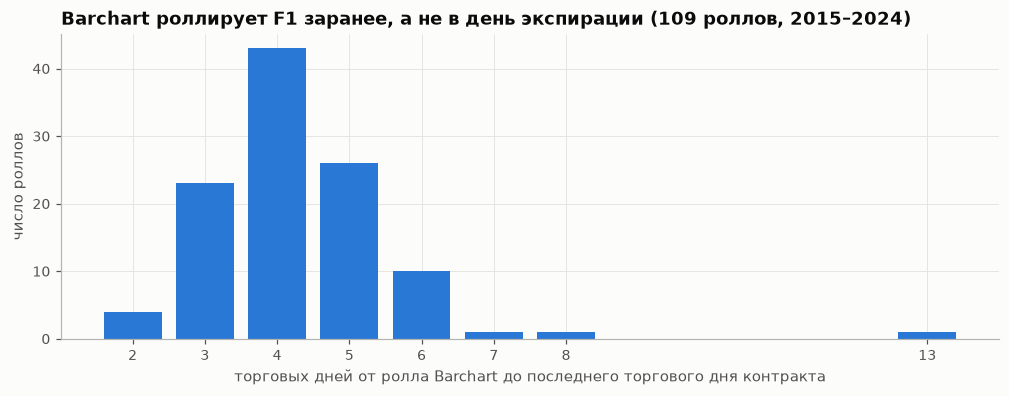

In [11]:
# Детектор по форме кривой: при ролле новый F_k = вчерашний F_{k+1}, значит сегодняшний спрэд (k, k+1)
# должен быть ближе к вчерашнему спрэду (k+1, k+2), чем к вчерашнему (k, k+1).
ADJ = ["spread_f1_f2", "spread_f2_f3", "spread_f3_f4", "spread_f4_f5", "spread_f5_f6"]
E_stay = sum((bc[ADJ[k]] - bc[ADJ[k]].shift()).abs() for k in range(4))
E_roll = sum((bc[ADJ[k]] - bc[ADJ[k + 1]].shift()).abs() for k in range(4))
bc["roll_score"] = E_stay - E_roll  # > 0 — гипотеза ролла лучше


def pick_by_score(candidates):
    return bc.loc[candidates, "roll_score"].idxmax()


# Ground truth: переход состояния 1 -> 2 (Barchart перешёл на следующий контракт раньше EIA).
# Если между последним днём «1» и первым днём «2» есть дни без сверки (нет в EIA или EIA F1 = F2),
# выбираем день ролла среди кандидатов по детектору.
truth, ambiguous = [], []
kd = known.index
for a, b in zip(kd[:-1], kd[1:]):
    if known[a] == 1 and known[b] == 2:
        cands = days[(days > a) & (days <= b)]
        truth.append(cands[0] if len(cands) == 1 else pick_by_score(cands))
        if len(cands) > 1:
            ambiguous.append((a.date(), b.date(), truth[-1].date()))
truth = pd.DatetimeIndex(truth)
print(f"дней ролла Barchart на пересечении с EIA: {len(truth)}; неоднозначных (решены детектором): {ambiguous}")

exp_after = pd.Series([expiry[expiry >= t][0] for t in truth], index=truth)
offset = pos[exp_after.values].values - pos[truth].values  # торговых дней от ролла до экспирации
off_tbl = pd.Series(offset).value_counts().sort_index()
print("за сколько торговых дней до экспирации Barchart переходит на следующий контракт:")
print(off_tbl.to_string())
print("день месяца ролла: медиана", int(np.median(truth.day)), "| диапазон", truth.day.min(), "–", truth.day.max())
print("выброс:", [(t.date(), int(o)) for t, o in zip(truth, offset) if o > 8])

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(off_tbl.index, off_tbl.values, color=u.SERIES[0])
ax.set_xticks(off_tbl.index)
ax.set_xlabel("торговых дней от ролла Barchart до последнего торгового дня контракта")
ax.set_ylabel("число роллов")
ax.set_title(f"Barchart роллирует F1 заранее, а не в день экспирации ({len(truth)} роллов, 2015–2024)")
plt.show()

In [12]:
# Проверка детектора на ground truth: в окне 3–6 торговых дней до экспирации берём день с max roll_score
def detect_in_window(exp_dates, lo=3, hi=6):
    out = []
    for x in exp_dates:
        i = pos[x]
        cands = days[max(i - hi, 1): i - lo + 1]
        if len(cands):
            out.append(pick_by_score(cands))
    return pd.DatetimeIndex(out)


det_all = detect_in_window(expiry)
in_ov = (det_all >= truth.min() - pd.Timedelta(days=20)) & (det_all <= EIA_END)
det_ov = det_all[in_ov & det_all.isin(days[(days > EIA_START) & (days <= EIA_END)])]
hit = det_ov.isin(truth).sum()
global_pos = (bc.loc[EIA_START:EIA_END, "roll_score"] > 0).sum()
print(f"детектор (окно 3–6 дн. до экспирации): угадано {hit} из {len(truth)} роллов ({hit / len(truth):.0%})")
print(f"для сравнения: дней с roll_score > 0 на пересечении — {global_pos} (без окна детектор бесполезен)")
cont_truth = (bc["spread_f2_f3"].shift() - bc["spread_f1_f2"].shift()).loc[truth].abs()
print(f"загрязнение Δ(F1−F2) в истинный день ролла |s23 − s12|(t−1): медиана {cont_truth.median():.3f}, "
      f"среднее {cont_truth.mean():.3f}, макс {cont_truth.max():.2f} $")

# Итоговая разметка: ground truth на пересечении, детектор вне его
outside = (det_all < EIA_START) | (det_all > EIA_END)
roll_days = truth.union(det_all[outside])
bc["roll"] = bc.index.isin(roll_days)
bc["roll_src"] = np.where(bc.index.isin(truth), "EIA-сверка", np.where(bc["roll"], "детектор", ""))
# Консервативное «окно ролла»: 2–6 торговых дней до экспирации (покрывает 106 из 109 известных роллов)
win_idx = set()
for x in expiry:
    i = pos[x]
    win_idx.update(range(max(i - 6, 0), i - 1))
bc["roll_window"] = np.isin(np.arange(len(days)), sorted(win_idx))
print(f"\nвсего дней ролла: {bc['roll'].sum()} (EIA-сверка {len(truth)}, детектор {outside.sum()}: "
      f"{[d.date() for d in det_all[outside]][:3]} …)")
print(f"дней в окне ролла: {bc['roll_window'].sum()} ({bc['roll_window'].mean():.0%} всех дней); "
      f"известных роллов внутри окна: {bc.loc[truth, 'roll_window'].sum()} из {len(truth)}")

детектор (окно 3–6 дн. до экспирации): угадано 84 из 109 роллов (77%)
для сравнения: дней с roll_score > 0 на пересечении — 416 (без окна детектор бесполезен)
загрязнение Δ(F1−F2) в истинный день ролла |s23 − s12|(t−1): медиана 0.110, среднее 0.179, макс 2.82 $

всего дней ролла: 142 (EIA-сверка 109, детектор 33: [datetime.date(2015, 1, 12), datetime.date(2015, 2, 17), datetime.date(2024, 4, 17)] …)
дней в окне ролла: 710 (24% всех дней); известных роллов внутри окна: 106 из 109


### 3.1. Загрязнение `delta_spread_*` роллами и «same-contract» изменения

В день ролла `delta_spread_f1_f2` = (F1−F2)_t − (F1−F2)_{t−1} сравнивает **разные пары контрактов**.
Same-contract изменение: в день ролла (F1−F2)_t − (F2−F3)_{t−1}, в остальные дни — обычный diff.
Для F1−F6 и F1−F12 так сделать нельзя (нет F7 и F13) — в дни ролла ставим NaN.
Аналогично цена: ΔF1 = F1_t − F2_{t−1} в день ролла.

In [13]:
F = {k: bc[f"wti_f{k}"] for k in (1, 2, 3, 4, 5, 6, 12)}
roll = bc["roll"]


def clean_delta(a, b):
    """Same-contract изменение спрэда F_a − F_b; NaN в день ролла, если нет F_{b+1}."""
    s = F[a] - F[b]
    naive = s.diff()
    alt = s - (F[a + 1] - F[b + 1]).shift() if (b + 1) in F else pd.Series(np.nan, index=days)
    return naive.where(~roll, alt)


PAIRS = {"f1_f2": (1, 2), "f2_f3": (2, 3), "f1_f3": (1, 3), "f1_f6": (1, 6), "f1_f12": (1, 12)}
for name, (a, b) in PAIRS.items():
    bc[f"dclean_{name}"] = clean_delta(a, b)
bc["dF1_clean"] = F[1].diff().where(~roll, F[1] - F[2].shift())
bc["dF1_naive"] = F[1].diff()

rows = []
for name in PAIRS:
    naive = bc[f"delta_spread_{name}"]
    clean = bc[f"dclean_{name}"]
    r, nr = naive[roll], naive[~roll]
    rows.append(
        {
            "спрэд": name,
            "медиана |Δ| ролл": r.abs().median(),
            "медиана |Δ| прочие": nr.abs().median(),
            "среднее |Δ| ролл": r.abs().mean(),
            "среднее |Δ| прочие": nr.abs().mean(),
            "ролл/прочие (среднее)": r.abs().mean() / nr.abs().mean(),
            "среднее |Δ| ролл, same-contract": clean[roll].abs().mean(),
            "доля Σ Δ² от дней ролла": (r**2).sum() / (naive**2).sum(),
            "корр. naive vs clean": naive.corr(clean) if clean[roll].notna().any() else np.nan,
        }
    )
rows.append(
    {
        "спрэд": "цена F1",
        "медиана |Δ| ролл": bc.loc[roll, "dF1_naive"].abs().median(),
        "медиана |Δ| прочие": bc.loc[~roll, "dF1_naive"].abs().median(),
        "среднее |Δ| ролл": bc.loc[roll, "dF1_naive"].abs().mean(),
        "среднее |Δ| прочие": bc.loc[~roll, "dF1_naive"].abs().mean(),
        "ролл/прочие (среднее)": bc.loc[roll, "dF1_naive"].abs().mean() / bc.loc[~roll, "dF1_naive"].abs().mean(),
        "среднее |Δ| ролл, same-contract": bc.loc[roll, "dF1_clean"].abs().mean(),
        "доля Σ Δ² от дней ролла": (bc.loc[roll, "dF1_naive"] ** 2).sum() / (bc["dF1_naive"] ** 2).sum(),
        "корр. naive vs clean": bc["dF1_naive"].corr(bc["dF1_clean"]),
    }
)
contam = pd.DataFrame(rows).set_index("спрэд")
print(f"дней ролла: {roll.sum()} из {len(bc)} ({roll.mean():.1%})")
print(rnd(contam, 3).to_string())

дней ролла: 142 из 2981 (4.8%)
         медиана |Δ| ролл  медиана |Δ| прочие  среднее |Δ| ролл  среднее |Δ| прочие  ролл/прочие (среднее)  среднее |Δ| ролл, same-contract  доля Σ Δ² от дней ролла  корр. naive vs clean
спрэд                                                                                                                                                                                     
f1_f2               0.120                0.04             0.234               0.095                  2.466                            0.071                    0.147                 0.934
f2_f3               0.100                0.04             0.167               0.084                  1.990                            0.064                    0.128                 0.945
f1_f3               0.210                0.08             0.367               0.175                  2.098                            0.134                    0.127                 0.946
f1_f6               0.355         

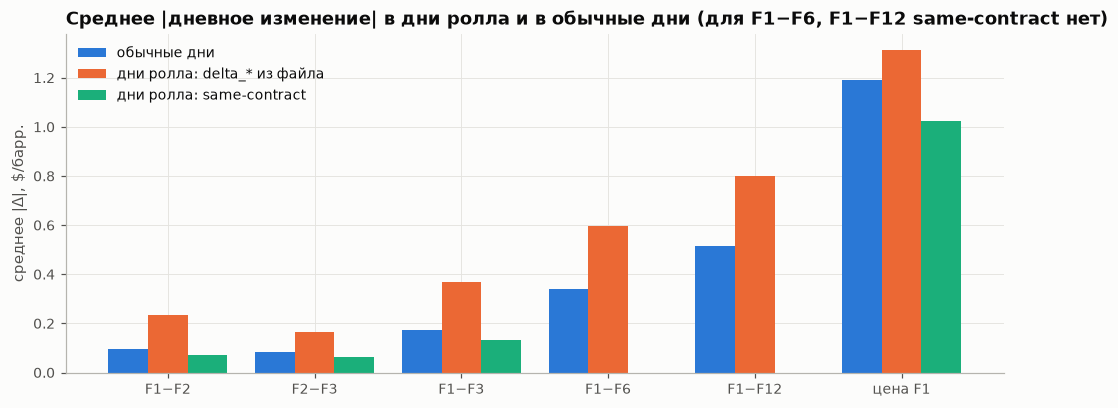

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
labels = list(PAIRS) + ["цена F1"]
x = np.arange(len(labels))
w = 0.27
ax.bar(x - w, contam["среднее |Δ| прочие"], w, color=u.SERIES[0], label="обычные дни")
ax.bar(x, contam["среднее |Δ| ролл"], w, color=u.SERIES[1], label="дни ролла: delta_* из файла")
ax.bar(x + w, contam["среднее |Δ| ролл, same-contract"], w, color=u.SERIES[2], label="дни ролла: same-contract")
ax.set_xticks(x, ["F1−F2", "F2−F3", "F1−F3", "F1−F6", "F1−F12", "цена F1"])
ax.set_ylabel("среднее |Δ|, $/барр.")
ax.set_title("Среднее |дневное изменение| в дни ролла и в обычные дни (для F1−F6, F1−F12 same-contract нет)")
ax.legend(loc="upper left")
plt.show()

In [15]:
# Валидация same-contract формулы против EIA: Barchart F1 в день t — это EIA-контракт j = state_t;
# тот же контракт в t−1 имеет индекс j + 1, если EIA роллировала в день t.
prev_day = pd.Series(days[:-1], index=days[1:])
val = []
for t in ov.index[ov["state"].isin([1, 2])]:
    if t not in prev_day.index:
        continue
    tp = prev_day[t]
    if tp not in eia.index:
        continue
    j = int(ov.loc[t, "state"])
    jp = j + (1 if t in eia_roll_obs else 0)
    if jp + 1 > 4:
        continue
    e_same = (eia.loc[t, f"wti_f{j}"] - eia.loc[t, f"wti_f{j + 1}"]) - (
        eia.loc[tp, f"wti_f{jp}"] - eia.loc[tp, f"wti_f{jp + 1}"]
    )
    val.append((t, e_same, bc.loc[t, "dclean_f1_f2"], bc.loc[t, "delta_spread_f1_f2"], bc.loc[t, "roll"]))
val = pd.DataFrame(val, columns=["day", "eia_same", "bc_clean", "bc_naive", "roll"]).set_index("day")
ok_clean = ((val["bc_clean"] - val["eia_same"]).abs() < 0.006).mean()
ok_naive = ((val["bc_naive"] - val["eia_same"]).abs() < 0.006).mean()
print(f"дней в проверке: {len(val)} (из них роллов Barchart: {val['roll'].sum()})")
print(f"same-contract Δ(F1−F2) Barchart = same-contract Δ по EIA: {ok_clean:.2%} дней; "
      f"для delta_spread_f1_f2 из файла: {ok_naive:.2%}")
print("макс. |расхождение| clean:", round((val["bc_clean"] - val["eia_same"]).abs().max(), 4))

дней в проверке: 2263 (из них роллов Barchart: 108)
same-contract Δ(F1−F2) Barchart = same-contract Δ по EIA: 100.00% дней; для delta_spread_f1_f2 из файла: 95.45%
макс. |расхождение| clean: 0.0


**Вывод.**
- На 2287 общих днях Barchart F1 **точно** равен либо EIA F1 (1704 дня), либо EIA F2 (572 дня; ещё 11 дней EIA F1 = F2),
  «ни с одним» — 0. Значит, close Barchart — это те же расчётные цены, а различие только в правиле ролла.
- Календарь экспираций по правилу CME (3 рабочих дня до 25-го, 4 — если 25-е не рабочий) совпал со всеми 110 роллами EIA.
- Barchart переходит на следующий контракт **заранее**: за 2–8 торговых дней до экспирации (мода — 4 дня, 43 из 109;
  3–5 дней — 92 из 109), обычно 12–17 числа (медиана 15). Выброс — 2020-04-30 (за 13 дней до экспирации CLM20).
  Т.е. примерно в 25% дней Barchart F1 — это **второй** по сроку контракт.
- Детектор ролла по форме кривой (без EIA) угадывает только 84 из 109 роллов (77%): при почти линейной кривой ролл
  не виден. Поэтому разметка `roll` = точные дни по EIA (109) + детектор вне пересечения (33 дня: янв.–февр. 2015 и
  апр. 2024 – окт. 2026, точность ≈77%). Консервативная альтернатива — `roll_window` (2–6 дней до экспирации,
  24% всех дней, покрывает 106 из 109 известных роллов).
- **`delta_spread_*` загрязнены**: в дни ролла (4,8% дней) среднее |Δ(F1−F2)| = 0,234 $ против 0,095 $ в обычные дни
  (×2,5; медианы 0,12 vs 0,04), и на эти дни приходится 14,7% суммы Δ². Для F1−F3 ×2,1, F1−F6 ×1,75, F1−F12 ×1,55;
  цена F1 ×1,10. После same-contract коррекции |Δ(F1−F2)| в дни ролла = 0,071 $ — как в обычные дни.
- Same-contract Δ(F1−F2) по Barchart совпал с same-contract Δ по EIA в 100% из 2263 проверенных дней (макс. расхождение 0,0),
  а `delta_spread_f1_f2` из файла — только в 95,45%: все расхождения приходятся на дни ролла.

**Рекомендация:** для изменений спрэда использовать same-contract Δ (`dclean_*` здесь): в день ролла
(F1−F2)_t − (F2−F3)_{t−1}. Для F1−F6 и F1−F12 (нет F7/F13) — исключать дни ролла. `delta_spread_*` из файла не использовать.

## 4. Barchart vs EIA на пересечении (2015-02-19 … 2024-04-05)

In [16]:
b_days = set(days[(days >= EIA_START) & (days <= EIA_END)])
e_days = set(eia.index)
only_eia = sorted(e_days - b_days)
only_bc = sorted(b_days - e_days)
print(f"дней: Barchart {len(b_days)}, EIA {len(e_days)}, общих {len(b_days & e_days)}")
print(f"только в EIA: {len(only_eia)} — {[d.date() for d in only_eia[:4]]} … {only_eia[-1].date()}")
stale = [(eia.loc[d, ["wti_f1", "wti_f2", "wti_f3", "wti_f4"]].values ==
          eia.shift().loc[d, ["wti_f1", "wti_f2", "wti_f3", "wti_f4"]].values).all() for d in only_eia]
print(f"  из них цены F1–F4 копируют предыдущий день: {sum(stale)} из {len(only_eia)}")
print(f"  праздники: {sorted(set(fed.get(d, 'Good Friday' if d in good_fri else '?') for d in only_eia))}")
print(f"только в Barchart: {len(only_bc)} — {[d.date() for d in only_bc]}")
print("  праздники:", pd.Series([fed.get(d, "не праздник") for d in only_bc]).value_counts().to_dict())

дней: Barchart 2299, EIA 2305, общих 2287
только в EIA: 18 — [datetime.date(2018, 1, 1), datetime.date(2018, 1, 15), datetime.date(2018, 2, 19), datetime.date(2018, 3, 30)] … 2019-12-25
  из них цены F1–F4 копируют предыдущий день: 18 из 18
  праздники: ['Birthday of Martin Luther King, Jr.', 'Christmas Day', 'Good Friday', 'Independence Day', 'Labor Day', 'Memorial Day', "New Year's Day", 'Thanksgiving Day', "Washington's Birthday"]
только в Barchart: 12 — [datetime.date(2015, 10, 12), datetime.date(2015, 11, 11), datetime.date(2016, 6, 2), datetime.date(2016, 10, 10), datetime.date(2016, 11, 11), datetime.date(2016, 11, 25), datetime.date(2017, 10, 9), datetime.date(2017, 11, 10), datetime.date(2017, 11, 24), datetime.date(2019, 11, 29), datetime.date(2020, 11, 27), datetime.date(2021, 11, 26)]
  праздники: {'не праздник': 6, 'Columbus Day': 3, 'Veterans Day': 3}


In [17]:
cmp_rows = []
for k in (1, 2, 3, 4):
    d = ov[f"wti_f{k}"] - ov[f"eia_wti_f{k}"]
    cmp_rows.append({"ряд": f"F{k}", "доля точных совпадений": (d.abs() < 0.005).mean(), "MAE": d.abs().mean(),
                     "медиана |Δ|": d.abs().median(), "макс |Δ|": d.abs().max(), "день макс": d.abs().idxmax().date(),
                     "корр.": ov[f"wti_f{k}"].corr(ov[f"eia_wti_f{k}"])})
ds = ov["spread_f1_f2"] - eia["spread_1_2"].reindex(ov.index)
cmp_rows.append({"ряд": "F1−F2", "доля точных совпадений": (ds.abs() < 0.005).mean(), "MAE": ds.abs().mean(),
                 "медиана |Δ|": ds.abs().median(), "макс |Δ|": ds.abs().max(), "день макс": ds.abs().idxmax().date(),
                 "корр.": ov["spread_f1_f2"].corr(eia["spread_1_2"].reindex(ov.index))})
cmp_tbl = pd.DataFrame(cmp_rows).set_index("ряд")
print(rnd(cmp_tbl, 4).to_string())
print(f"\nв дни, когда Barchart на ближнем контракте (state=1, {int((ov['state'] == 1).sum())} дн.), "
      f"F1–F4 совпадают точно: {((ov.loc[ov['state'] == 1, ['wti_f1', 'wti_f2', 'wti_f3', 'wti_f4']].values - ov.loc[ov['state'] == 1, ['eia_wti_f1', 'eia_wti_f2', 'eia_wti_f3', 'eia_wti_f4']].values).__abs__() < 0.005).mean():.2%}")
d_s12 = ds[ov["state"] == 2]
print(f"в дни state=2: F1−F2 Barchart минус EIA — медиана {d_s12.median():.3f}, "
      f"5% / 95%: {d_s12.quantile(0.05):.3f} / {d_s12.quantile(0.95):.3f}")
print("\nкрупнейшие расхождения F1−F2 (Barchart − EIA):")
print(rnd(pd.DataFrame({"BC F1−F2": ov["spread_f1_f2"], "EIA F1−F2": eia["spread_1_2"].reindex(ov.index),
                        "разница": ds}).loc[ds.abs().nlargest(6).index], 2).to_string())

       доля точных совпадений     MAE  медиана |Δ|  макс |Δ|   день макс   корр.
ряд                                                                             
F1                     0.7499  0.1725          0.0     58.06  2020-04-20  0.9976
F2                     0.7481  0.1606          0.0      7.12  2020-04-21  0.9997
F3                     0.7477  0.1503          0.0      3.23  2022-05-20  0.9998
F4                     0.7490  0.1403          0.0      3.02  2022-03-21  0.9998
F1−F2                  0.7512  0.0815          0.0     52.21  2020-04-20  0.7012

в дни, когда Barchart на ближнем контракте (state=1, 1704 дн.), F1–F4 совпадают точно: 100.00%
в дни state=2: F1−F2 Barchart минус EIA — медиана 0.090, 5% / 95%: -0.349 / 0.590

крупнейшие расхождения F1−F2 (Barchart − EIA):
             BC F1−F2  EIA F1−F2  разница
trading_day                              
2020-04-20      -5.85     -58.06    52.21
2020-04-21      -7.12      -1.56    -5.56
2020-04-17      -4.39      -6.76     2.

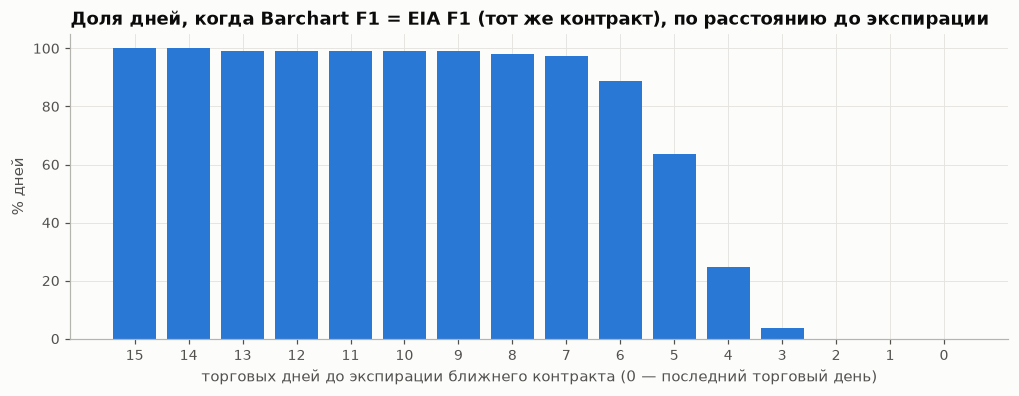

to_exp                0    1    2     3     4     5     6     7     8     9     10    11    12    13   14   15
доля BC F1 = EIA F1  0.0  0.0  0.0  0.04  0.25  0.64  0.89  0.97  0.98  0.99  0.99  0.99  0.99  0.99  1.0  1.0


In [18]:
# Доля совпадения BC F1 с EIA F1 в зависимости от расстояния до экспирации
exp_ser = pd.Series(expiry, index=expiry)
next_exp = exp_ser.reindex(days, method="bfill").dropna()
to_exp = pos[next_exp.values].values - pos[next_exp.index].values  # торговых дней до экспирации (0 = в день экспирации)
ov["to_exp"] = pd.Series(to_exp, index=next_exp.index).reindex(ov.index)
prof = ov[ov["state"].isin([1, 2])].groupby("to_exp")["state"].apply(lambda s: (s == 1).mean())
prof = prof.loc[0:15]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(prof.index, prof.values * 100, color=u.SERIES[0])
ax.set_xticks(prof.index)
ax.invert_xaxis()
ax.set_xlabel("торговых дней до экспирации ближнего контракта (0 — последний торговый день)")
ax.set_ylabel("% дней")
ax.set_title("Доля дней, когда Barchart F1 = EIA F1 (тот же контракт), по расстоянию до экспирации")
plt.show()
print(rnd(prof.to_frame("доля BC F1 = EIA F1"), 2).T.to_string())

In [19]:
# EIA тоже содержит роллы: в первый день после экспирации delta_spread_1_2 сравнивает разные контракты
eia_roll_own = pd.DatetimeIndex([eia.index[eia.index > x][0] for x in expiry if EIA_START < x < EIA_END])
e_is_roll = eia.index.isin(eia_roll_own)
de = eia["delta_spread_1_2"]
print(f"EIA: роллов {e_is_roll.sum()}; среднее |Δ(F1−F2)| в день ролла {de[e_is_roll].abs().mean():.3f} "
      f"vs прочие {de[~e_is_roll].abs().mean():.3f} (x{de[e_is_roll].abs().mean() / de[~e_is_roll].abs().mean():.1f})")
exp_in = expiry[(expiry >= EIA_START) & (expiry <= EIA_END)]
print(f"EIA F1−F2 в последний торговый день контракта: медиана |s12| {eia.loc[eia.index.isin(exp_in), 'spread_1_2'].abs().median():.3f} "
      f"vs прочие дни {eia.loc[~eia.index.isin(exp_in), 'spread_1_2'].abs().median():.3f}")
print("нулевых изменений F1 в EIA (застывшие цены):", int((eia["wti_f1"].diff() == 0).sum()),
      "| в Barchart:", int((bc["wti_f1"].diff() == 0).sum()))

EIA: роллов 110; среднее |Δ(F1−F2)| в день ролла 0.345 vs прочие 0.127 (x2.7)
EIA F1−F2 в последний торговый день контракта: медиана |s12| 0.365 vs прочие дни 0.320
нулевых изменений F1 в EIA (застывшие цены): 29 | в Barchart: 4


**Вывод.**
- Даты: 2287 общих дней; сдвига дат нет (на днях без ролла цены совпадают до цента). В EIA 18 лишних строк — биржевые
  праздники 2018–2019 (New Year, MLK, Presidents Day, Good Friday, Memorial, July 4, Labor, Thanksgiving, Christmas),
  где F1–F4 скопированы с предыдущего дня (18 из 18) — это нулевые Δ, которые надо удалить. В Barchart 12 дней, которых нет
  в EIA: 3 Columbus Day, 3 Veterans Day, 5 «чёрных пятниц» после Thanksgiving и 2016-06-02 — это реальные торговые дни.
- Уровни F1–F4 совпадают точно в ~75% дней (MAE F1 = 0,17 $, у F1−F2 — 0,08 $); в дни, когда Barchart ещё на ближнем
  контракте, совпадение 100%. Все расхождения — окно между роллом Barchart и экспирацией: доля дней с тем же контрактом
  ≥97% за 7+ дней до экспирации, 89% за 6 дней, 64% за 5, 25% за 4, 4% за 3 и 0% за 0–2 дня. В эти дни F1−F2 Barchart
  минус EIA: медиана +0,09 $ (5–95%: −0,35…+0,59). Крупнейшее расхождение — 2020-04-20: 52,21 $ (EIA −58,06 против −5,85).
- У EIA своя проблема роллов: в первый день после экспирации |Δ(F1−F2)| = 0,345 $ против 0,127 $ в остальные дни (×2,7),
  и EIA держит в F1 истекающий, неликвидный контракт до последнего дня торгов.

**Чему доверять:** цены идентичны, поэтому вопрос только в конвенции. Barchart покрывает весь период (EIA заканчивается
2024-04-05), не содержит застывших праздничных строк и не держит истекающий контракт, поэтому основной источник —
Barchart с явной разметкой роллов и same-contract Δ. EIA полезна как ground truth идентичности контракта до 2024-04.

## 5. Распределение дневного Δspread

Дальше везде используется same-contract Δ(F1−F2) (`dclean_f1_f2`), если не сказано иное.

In [20]:
def dist_stats(x):
    x = x.dropna()
    z = (x - x.mean()) / x.std()
    jb = stats.jarque_bera(x)
    return pd.Series({"N": len(x), "среднее": x.mean(), "std": x.std(), "асимметрия": stats.skew(x),
                      "эксцесс (excess)": stats.kurtosis(x), "q01": x.quantile(0.01), "q99": x.quantile(0.99),
                      "min": x.min(), "max": x.max(), "доля |z|>3, %": (z.abs() > 3).mean() * 100,
                      "JB p": jb.pvalue})


dist_tbl = pd.DataFrame({
    "Δ(F1−F2) из файла": dist_stats(bc["delta_spread_f1_f2"]),
    "Δ(F1−F2) same-contract": dist_stats(bc["dclean_f1_f2"]),
    "Δ(F1−F2) clean без 2020": dist_stats(bc.loc[bc.index.year != 2020, "dclean_f1_f2"]),
    "Δ(F1−F3) same-contract": dist_stats(bc["dclean_f1_f3"]),
    "ΔF1 same-contract": dist_stats(bc["dF1_clean"]),
}).T
print(rnd(dist_tbl, 3).to_string())
print("\nдля нормального распределения доля |z|>3 = 0.27%")

                              N  среднее    std  асимметрия  эксцесс (excess)    q01    q99    min    max  доля |z|>3, %  JB p
Δ(F1−F2) из файла        2980.0    0.001  0.265      -3.705           198.044 -0.622  0.684  -6.91   4.26          1.577   0.0
Δ(F1−F2) same-contract   2980.0   -0.004  0.246      -5.503           250.039 -0.590  0.614  -6.91   4.26          1.644   0.0
Δ(F1−F2) clean без 2020  2727.0   -0.003  0.242      -6.275           287.895 -0.497  0.565  -6.91   4.26          1.503   0.0
Δ(F1−F3) same-contract   2980.0   -0.004  0.427      -5.431           210.033 -1.212  1.112 -11.58   6.24          1.711   0.0
ΔF1 same-contract        2980.0    0.018  1.749      -0.906            11.103 -4.944  4.444 -18.54  11.42          1.477   0.0

для нормального распределения доля |z|>3 = 0.27%


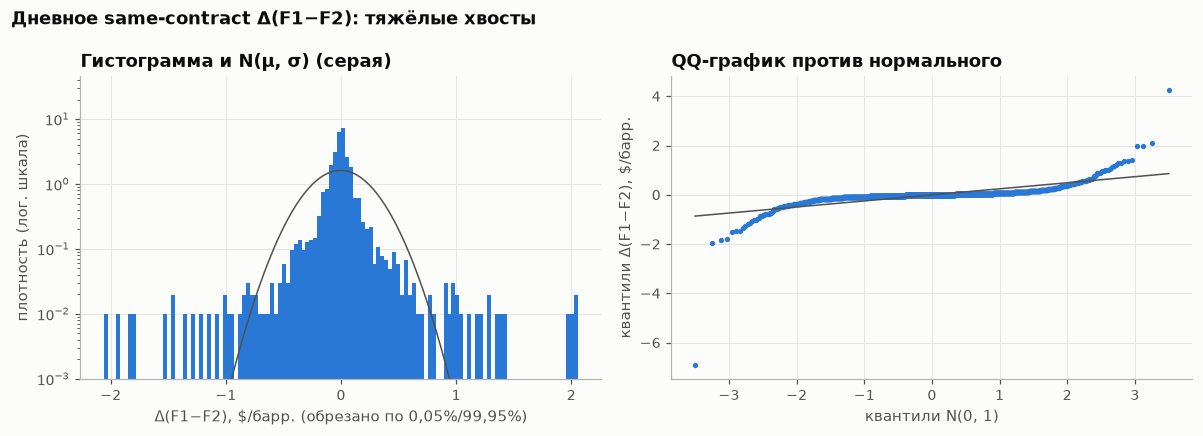

In [21]:
x = bc["dclean_f1_f2"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lim = x.quantile([0.0005, 0.9995]).abs().max()
bins = np.linspace(-lim, lim, 121)
axes[0].hist(x.clip(-lim, lim), bins=bins, density=True, color=u.SERIES[0])
grid = np.linspace(-lim, lim, 400)
axes[0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), color=u.INK_MUTED, lw=1)
axes[0].set_yscale("log")
axes[0].set_ylim(1e-3, None)
axes[0].set_xlabel("Δ(F1−F2), $/барр. (обрезано по 0,05%/99,95%)")
axes[0].set_ylabel("плотность (лог. шкала)")
axes[0].set_title("Гистограмма и N(μ, σ) (серая)")
(osm, osr), _ = stats.probplot(x, dist="norm")
axes[1].scatter(osm, osr, s=6, color=u.SERIES[0])
axes[1].plot(osm, osm * x.std() + x.mean(), color=u.INK_MUTED, lw=1)
axes[1].set_xlabel("квантили N(0, 1)")
axes[1].set_ylabel("квантили Δ(F1−F2), $/барр.")
axes[1].set_title("QQ-график против нормального")
fig.suptitle("Дневное same-contract Δ(F1−F2): тяжёлые хвосты", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

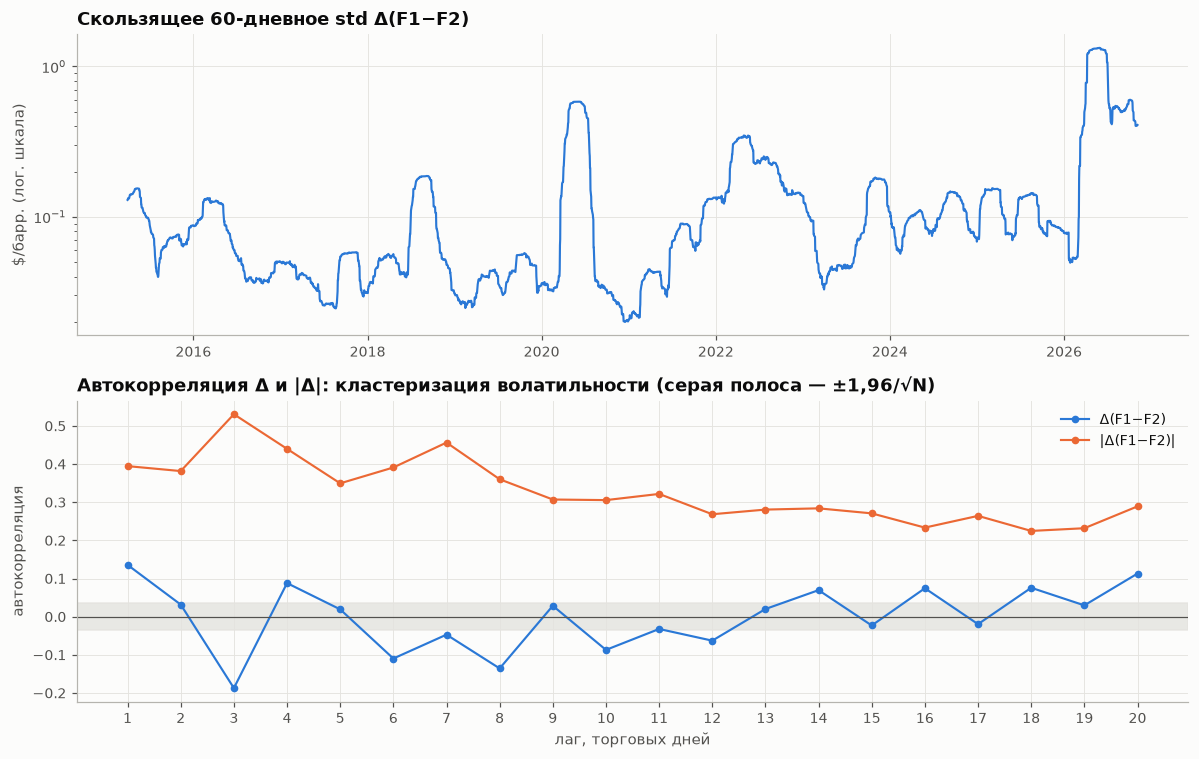

          lb_stat  lb_pvalue
Δ   5    186.7454        0.0
    10   309.3834        0.0
|Δ| 5   2683.0234        0.0
    10  4712.1717        0.0
Δ²  5    414.9613        0.0
    10   523.7778        0.0

эксцесс Δ/std(предыдущие 60 дн.): 13.18 (у сырого Δ: 250.04)
ACF |Δ| на лагах 1–20: от 0.225 до 0.531
скользящее 60-дн. std: min 0.020 (2020-12-15), max 1.329 (2026-05-28)
ACF Δ, лаги 1–3: все дни [ 0.136  0.032 -0.187] | без 2020 и 2026 [ 0.091  0.026 -0.019] | Δ/std60 [0.118 0.019 0.016]


In [22]:
roll_std = x.rolling(60).std()
ac_raw = acf(x, nlags=20, fft=True)[1:]
ac_abs = acf(x.abs(), nlags=20, fft=True)[1:]
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
axes[0].plot(roll_std.index, roll_std, color=u.SERIES[0])
axes[0].set_yscale("log")
axes[0].set_ylabel("$/барр. (лог. шкала)")
axes[0].set_title("Скользящее 60-дневное std Δ(F1−F2)")
lags = np.arange(1, 21)
axes[1].plot(lags, ac_raw, marker="o", color=u.SERIES[0], label="Δ(F1−F2)")
axes[1].plot(lags, ac_abs, marker="o", color=u.SERIES[1], label="|Δ(F1−F2)|")
band = 1.96 / np.sqrt(len(x))
axes[1].axhspan(-band, band, color=u.GRID, alpha=0.8)
axes[1].axhline(0, color=u.INK_MUTED, lw=0.8)
axes[1].set_xticks(lags)
axes[1].set_xlabel("лаг, торговых дней")
axes[1].set_ylabel("автокорреляция")
axes[1].set_title("Автокорреляция Δ и |Δ|: кластеризация волатильности (серая полоса — ±1,96/√N)")
axes[1].legend()
fig.tight_layout()
plt.show()

lb = pd.concat({
    "Δ": acorr_ljungbox(x, lags=[5, 10]),
    "|Δ|": acorr_ljungbox(x.abs(), lags=[5, 10]),
    "Δ²": acorr_ljungbox(x**2, lags=[5, 10]),
})
print(rnd(lb, 4).to_string())
z60 = (x / x.rolling(60).std().shift()).dropna()
print(f"\nэксцесс Δ/std(предыдущие 60 дн.): {stats.kurtosis(z60):.2f} (у сырого Δ: {stats.kurtosis(x):.2f})")
print(f"ACF |Δ| на лагах 1–20: от {ac_abs.min():.3f} до {ac_abs.max():.3f}")
print(f"скользящее 60-дн. std: min {roll_std.min():.3f} ({roll_std.idxmin().date()}), "
      f"max {roll_std.max():.3f} ({roll_std.idxmax().date()})")
calm = ~x.index.year.isin([2020, 2026])
print("ACF Δ, лаги 1–3: все дни", acf(x, nlags=3)[1:].round(3),
      "| без 2020 и 2026", acf(x[calm], nlags=3)[1:].round(3),
      "| Δ/std60", acf(z60, nlags=3)[1:].round(3))

по знаку спрэда накануне:
                N    std  mean_abs     kurt
режим                                      
бэквордация  1575  0.314     0.129  175.545
контанго     1398  0.134     0.054   71.251
ноль            7  0.043     0.037   -1.010

по модулю спрэда накануне (квинтили):
                  N    std    kurt
|s12| квинтиль                    
(-0.001, 0.16]  607  0.046   8.588
(0.16, 0.3]     589  0.057  18.919
(0.3, 0.544]    592  0.070   5.694
(0.544, 1.04]   598  0.116   7.990
(1.04, 13.94]   594  0.529  56.141

std по годам:
режим  бэквордация  контанго   ноль  всего
год                                       
2015           NaN     0.097    NaN  0.097
2016           NaN     0.075    NaN  0.075
2017         0.057     0.039    NaN  0.040
2018         0.112     0.033    NaN  0.099
2019         0.050     0.035  0.029  0.041
2020         0.029     0.292    NaN  0.284
2021         0.086     0.024    NaN  0.083
2022         0.238     0.074    NaN  0.229
2023         0.134     0.

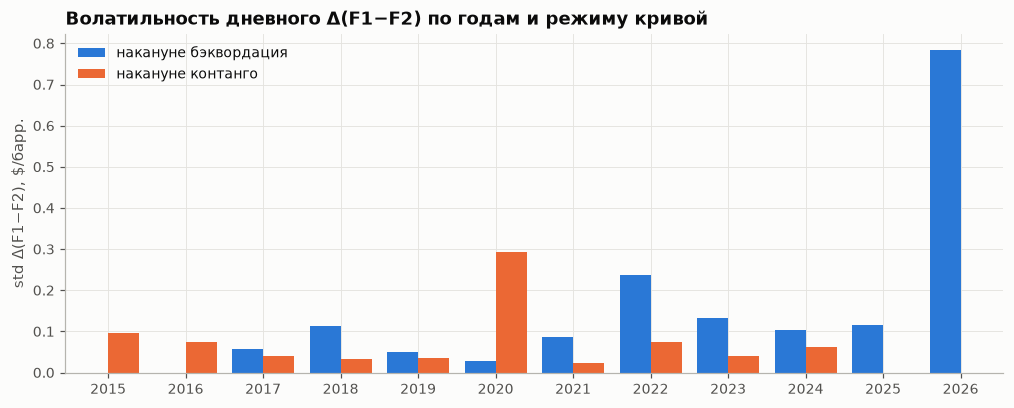

In [23]:
reg = pd.DataFrame({"d": bc["dclean_f1_f2"], "s_prev": bc["spread_f1_f2"].shift()}).dropna()
reg["режим"] = np.where(reg["s_prev"] > 0, "бэквордация", np.where(reg["s_prev"] < 0, "контанго", "ноль"))
reg["год"] = reg.index.year
by_regime = reg.groupby("режим")["d"].agg(N="size", std="std", mean_abs=lambda s: s.abs().mean(),
                                          kurt=lambda s: stats.kurtosis(s))
reg["|s12| квинтиль"] = pd.qcut(reg["s_prev"].abs(), 5)
by_level = reg.groupby("|s12| квинтиль", observed=True)["d"].agg(N="size", std="std",
                                                                 kurt=lambda s: stats.kurtosis(s))
by_year = reg.pivot_table(index="год", columns="режим", values="d", aggfunc="std")
by_year["всего"] = reg.groupby("год")["d"].std()
print("по знаку спрэда накануне:")
print(rnd(by_regime, 3).to_string())
print("\nпо модулю спрэда накануне (квинтили):")
print(rnd(by_level, 3).to_string())
print("\nstd по годам:")
print(rnd(by_year, 3).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
yrs = by_year.index.values
ax.bar(yrs - 0.2, by_year["бэквордация"], 0.4, color=u.SERIES[0], label="накануне бэквордация")
ax.bar(yrs + 0.2, by_year["контанго"], 0.4, color=u.SERIES[1], label="накануне контанго")
ax.set_xticks(yrs)
ax.set_ylabel("std Δ(F1−F2), $/барр.")
ax.set_title("Волатильность дневного Δ(F1−F2) по годам и режиму кривой")
ax.legend(loc="upper left")
plt.show()

**Вывод.**
- Хвосты экстремальные: у same-contract Δ(F1−F2) std 0,246 $, асимметрия −5,5, избыточный эксцесс 250;
  |z| > 3 в 1,64% дней (у нормального 0,27%); 1%/99% квантили −0,59/+0,61 $, но min −6,91 $ (2026-04-08),
  max +4,26 $ (2026-04-02). Без 2020 эксцесс не падает (288) — хвосты дают и 2026, и другие эпизоды. ΔF1 гораздо ближе
  к норме (эксцесс 11). Наивный `delta_spread_f1_f2` ещё и добавляет роллы (std 0,265 против 0,246).
- Сильная кластеризация волатильности: автокорреляция |Δ| 0,23–0,53 на лагах 1–20, Ljung–Box Q(10) для |Δ| = 4712;
  60-дневное std меняется от 0,020 $ (2020-12-15) до 1,329 $ (2026-05-28), т.е. в ~66 раз. Нормировка на std за
  предыдущие 60 дней снижает эксцесс с 250 до 13 — большая часть «тяжёлых хвостов» объясняется сменой режима волатильности.
- Сам Δ слабо положительно автокоррелирован на лаге 1 (0,14; без 2020/2026 — 0,09; после нормировки — 0,12);
  −0,19 на лаге 3 создают выбросы (без 2020/2026: −0,02).
- Режим: при бэквордации накануне std Δ = 0,314 $ против 0,134 $ при контанго (среднее |Δ| 0,129 против 0,054);
  волатильность растёт с модулем спрэда — от 0,046 $ в нижнем квинтиле |F1−F2| (≤ 0,16 $) до 0,529 $ в верхнем (> 1,04 $).
  По годам максимум в 2026 (0,78), 2020 (0,28, почти целиком в дни контанго) и 2022 (0,23); минимум в 2017 и 2019 (0,04).

## 6. Спрэд и запасы (недельные данные)

Неделя EIA заканчивается в пятницу (`period`); уровень спрэда берём на закрытие последнего торгового дня
≤ `period`. Недельное изменение спрэда — сумма same-contract дневных Δ за (прошлая пятница, пятница]
(обычный diff недельных уровней снова был бы загрязнён роллом). Запасы за неделю публикуются только в
следующую среду, поэтому одновременная корреляция описывает фундаментал, а не торгуемый сигнал;
лаг «спрэд за следующую неделю» содержит день публикации.

In [24]:
chain12 = bc["dclean_f1_f2"].fillna(0).cumsum()
wk = weekly[["period", "cushing_stocks_mmbbl", "crude_stocks_mmbbl", "cushing_stocks_change_mmbbl",
             "crude_stocks_change_mmbbl"]].copy().set_index("period").sort_index()
wk["s12"] = bc["spread_f1_f2"].reindex(wk.index, method="ffill")
wk["s16"] = bc["spread_f1_f6"].reindex(wk.index, method="ffill")
wk["d_s12"] = chain12.reindex(wk.index, method="ffill").diff()
wk["d_s12_next"] = wk["d_s12"].shift(-1)
wk["d_s12_prev"] = wk["d_s12"].shift(1)
wk = wk.iloc[1:]  # первая неделя без изменений запасов
print(f"недель: {len(wk)} ({wk.index.min().date()} … {wk.index.max().date()}); "
      f"пятница не торговый день: {(~wk.index.isin(days)).sum()}")


def corr_pair(a, b):
    d = pd.concat([a, b], axis=1).dropna()
    return pd.Series({"Пирсон": d.iloc[:, 0].corr(d.iloc[:, 1]),
                      "Спирмен": d.iloc[:, 0].corr(d.iloc[:, 1], method="spearman"), "N": len(d)})


ctab = pd.DataFrame({
    "уровень F1−F2 ~ Cushing": corr_pair(wk["s12"], wk["cushing_stocks_mmbbl"]),
    "уровень F1−F2 ~ коммерч.": corr_pair(wk["s12"], wk["crude_stocks_mmbbl"]),
    "уровень F1−F6 ~ Cushing": corr_pair(wk["s16"], wk["cushing_stocks_mmbbl"]),
    "уровень F1−F6 ~ коммерч.": corr_pair(wk["s16"], wk["crude_stocks_mmbbl"]),
    "ΔF1−F2 ~ ΔCushing (та же неделя)": corr_pair(wk["d_s12"], wk["cushing_stocks_change_mmbbl"]),
    "ΔF1−F2 ~ Δкоммерч. (та же неделя)": corr_pair(wk["d_s12"], wk["crude_stocks_change_mmbbl"]),
    "ΔF1−F2 след. недели ~ ΔCushing": corr_pair(wk["d_s12_next"], wk["cushing_stocks_change_mmbbl"]),
    "ΔF1−F2 след. недели ~ Δкоммерч.": corr_pair(wk["d_s12_next"], wk["crude_stocks_change_mmbbl"]),
    "ΔF1−F2 пред. недели ~ ΔCushing": corr_pair(wk["d_s12_prev"], wk["cushing_stocks_change_mmbbl"]),
}).T
print(rnd(ctab, 3).to_string())

ERAS = [("2015–2019", 2015, 2019), ("2020–2021", 2020, 2021), ("2022–2026", 2022, 2026)]
era_rows = {}
for name, a, b in ERAS:
    m = (wk.index.year >= a) & (wk.index.year <= b)
    era_rows[name] = {
        "N": int(m.sum()),
        "ур. F1−F2 ~ Cushing": wk.loc[m, "s12"].corr(wk.loc[m, "cushing_stocks_mmbbl"]),
        "ур. F1−F2 ~ коммерч.": wk.loc[m, "s12"].corr(wk.loc[m, "crude_stocks_mmbbl"]),
        "Δ ~ ΔCushing": wk.loc[m, "d_s12"].corr(wk.loc[m, "cushing_stocks_change_mmbbl"]),
        "Δ ~ Δкоммерч.": wk.loc[m, "d_s12"].corr(wk.loc[m, "crude_stocks_change_mmbbl"]),
    }
print("\nпо эпохам (Пирсон):")
print(rnd(pd.DataFrame(era_rows).T, 3).to_string())

недель: 609 (2015-02-27 … 2026-10-23); пятница не торговый день: 22
                                   Пирсон  Спирмен      N
уровень F1−F2 ~ Cushing            -0.585   -0.833  609.0
уровень F1−F2 ~ коммерч.           -0.382   -0.610  609.0
уровень F1−F6 ~ Cushing            -0.628   -0.757  609.0
уровень F1−F6 ~ коммерч.           -0.398   -0.534  609.0
ΔF1−F2 ~ ΔCushing (та же неделя)   -0.116   -0.204  609.0
ΔF1−F2 ~ Δкоммерч. (та же неделя)  -0.109   -0.145  609.0
ΔF1−F2 след. недели ~ ΔCushing     -0.046   -0.097  608.0
ΔF1−F2 след. недели ~ Δкоммерч.    -0.004   -0.038  608.0
ΔF1−F2 пред. недели ~ ΔCushing     -0.144   -0.175  608.0

по эпохам (Пирсон):
               N  ур. F1−F2 ~ Cushing  ур. F1−F2 ~ коммерч.  Δ ~ ΔCushing  Δ ~ Δкоммерч.
2015–2019  253.0               -0.691                -0.384        -0.132         -0.216
2020–2021  105.0               -0.488                -0.420        -0.367         -0.287
2022–2026  251.0               -0.202                -0.066     

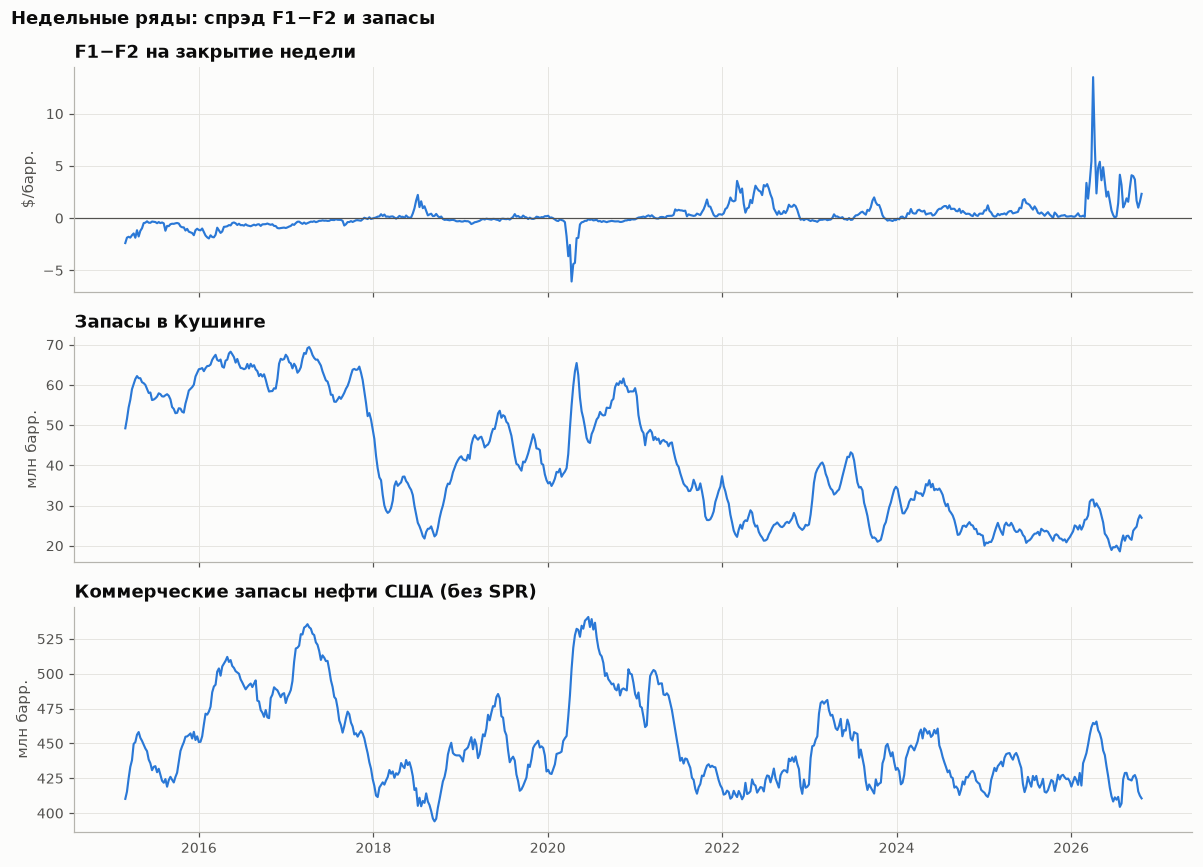

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
axes[0].plot(wk.index, wk["s12"], color=u.SERIES[0])
axes[0].axhline(0, color=u.INK_MUTED, lw=0.8)
axes[0].set_title("F1−F2 на закрытие недели")
axes[0].set_ylabel("$/барр.")
axes[1].plot(wk.index, wk["cushing_stocks_mmbbl"], color=u.SERIES[0])
axes[1].set_title("Запасы в Кушинге")
axes[1].set_ylabel("млн барр.")
axes[2].plot(wk.index, wk["crude_stocks_mmbbl"], color=u.SERIES[0])
axes[2].set_title("Коммерческие запасы нефти США (без SPR)")
axes[2].set_ylabel("млн барр.")
fig.suptitle("Недельные ряды: спрэд F1−F2 и запасы", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

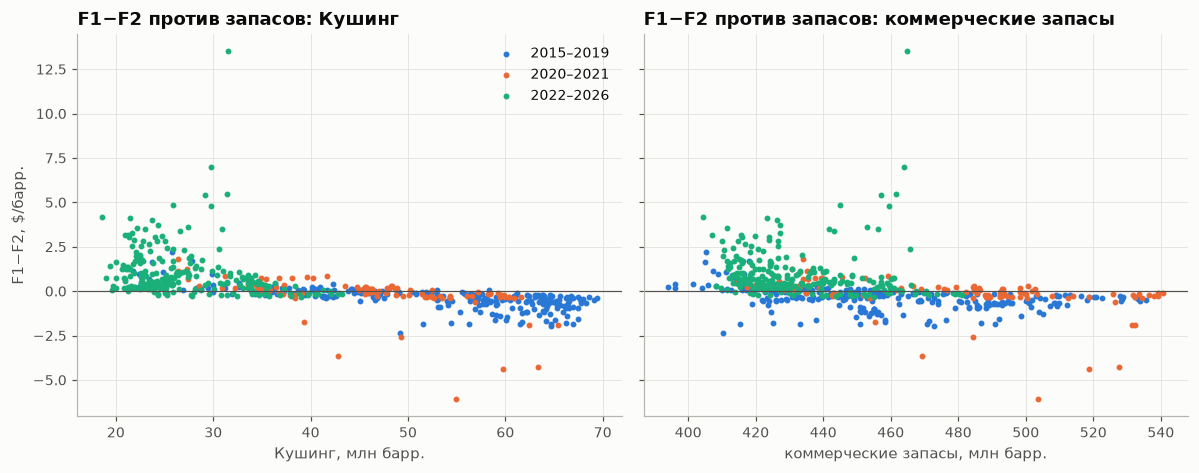

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, col, title in [(axes[0], "cushing_stocks_mmbbl", "Кушинг"), (axes[1], "crude_stocks_mmbbl", "коммерческие запасы")]:
    for i, (name, a, b) in enumerate(ERAS):
        m = (wk.index.year >= a) & (wk.index.year <= b)
        ax.scatter(wk.loc[m, col], wk.loc[m, "s12"], s=8, color=u.SERIES[i], label=name)
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_xlabel(f"{title}, млн барр.")
    ax.set_title(f"F1−F2 против запасов: {title}")
axes[0].set_ylabel("F1−F2, $/барр.")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

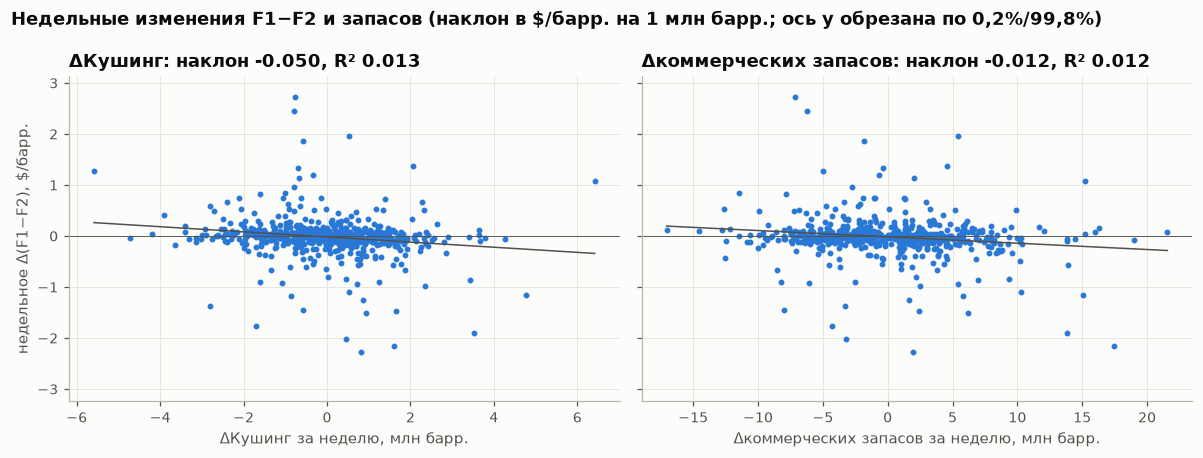

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, col, title in [(axes[0], "cushing_stocks_change_mmbbl", "ΔКушинг"),
                       (axes[1], "crude_stocks_change_mmbbl", "Δкоммерческих запасов")]:
    d = wk[[col, "d_s12"]].dropna()
    ax.scatter(d[col], d["d_s12"], s=8, color=u.SERIES[0])
    res = ols(d["d_s12"], d[col])
    gx = np.linspace(d[col].min(), d[col].max(), 50)
    ax.plot(gx, res.params["const"] + res.params[col] * gx, color=u.INK_MUTED, lw=1)
    ax.set_xlabel(f"{title} за неделю, млн барр.")
    ax.set_title(f"{title}: наклон {res.params[col]:.3f}, R² {res.rsquared:.3f}")
    ax.axhline(0, color=u.INK_MUTED, lw=0.6)
axes[0].set_ylabel("недельное Δ(F1−F2), $/барр.")
axes[0].set_ylim(wk["d_s12"].quantile(0.002), wk["d_s12"].quantile(0.998))
fig.suptitle("Недельные изменения F1−F2 и запасов (наклон в $/барр. на 1 млн барр.; ось y обрезана по 0,2%/99,8%)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Вывод.**
- Уровни: F1−F2 сильно и монотонно (но нелинейно) связан с запасами в Кушинге: Пирсон −0,585, Спирмен −0,833
  (609 недель); с коммерческими запасами слабее (−0,382 / −0,610); у F1−F6 с Кушингом −0,628 / −0,757. На scatter видно
  «режимы»: Кушинг > ~45 млн барр. (2015–2019) — контанго, < ~35 млн барр. (2022–2026) — бэквордация с выбросами вверх.
  Внутри эпох связь слабеет: для Кушинга −0,69 (2015–2019), −0,49 (2020–2021), −0,20 (2022–2026). Уровни нестационарны —
  корреляцию уровней нельзя читать как причинную.
- Изменения за ту же неделю: corr(ΔF1−F2, ΔКушинг) = −0,116 (Спирмен −0,204; наклон −0,050 $ на 1 млн барр.,
  R² 0,013), с Δкоммерческих −0,109 (наклон −0,012, R² 0,012); сильнее всего в 2020–2021 (−0,37 и −0,29).
- Изменение спрэда за **следующую** неделю (в неё попадает публикация этих запасов) почти не связано с ними (−0,046 и −0,004),
  а изменение за **предыдущую** неделю связано с ростом Кушинга сильнее (−0,144; Спирмен −0,175): спрэд падает раньше, чем
  запасы в Кушинге растут. Это согласуется с тем, что рынок узнаёт о потоках из других источников или что контанго само
  стимулирует закачку в хранилища (гипотеза, здесь не проверялась).

## 7. Event study: двигает ли inventory surprise спрэд в день релиза

Окно: закрытие предыдущего торгового дня → закрытие дня релиза EIA (same-contract Δ). Тайминг:
- Barchart close совпадает с расчётными ценами EIA (раздел 3) — это settlement NYMEX (~13:30 CT = 14:30 ET), даты — торговые дни CST;
- EIA выходит в 10:30 ET, т.е. до settlement дня релиза — реакция попадает в окно;
- API выходит во вторник в 16:30 ET, **после** вторничного settlement, поэтому реакция на (API − консенсус) тоже сидит в окне вт→ср.
  Отсюда разложение surprise = (API − консенсус) + (факт − API). При переносе релиза EIA на четверг/пятницу
  API обычно тоже сдвигается на день (допущение; в данных нет времени выхода API).

Ожидаемый знак: surprise > 0 (рост запасов сильнее ожиданий) — медвежий для ближнего контракта: спрэд F1−F2 и цена F1 падают;
draw (surprise < 0) — бэквордация расширяется. «Согласие знаков» = доля релизов, где sign(Δ) = −sign(surprise).

In [28]:
ev = releases.copy()
ev["i0"] = pos.reindex(ev["release_date"]).values
assert ev["i0"].notna().all()
ev["i0"] = ev["i0"].astype(int)
ev["prev_day"] = days[ev["i0"] - 1]
for lag, tag in [(-1, "m1"), (0, "0"), (1, "p1")]:
    idx = ev["i0"] + lag
    ok = (idx >= 0) & (idx < len(days))
    for col, out in [("dclean_f1_f2", "ds12"), ("dclean_f1_f3", "ds13"), ("dF1_clean", "dF1"),
                     ("delta_spread_f1_f2", "ds12_naive")]:
        vals = np.full(len(ev), np.nan)
        vals[ok] = bc[col].values[idx[ok]]
        ev[f"{out}_{tag}"] = vals
ev["roll0"] = bc["roll"].values[ev["i0"]]
ev["roll_window0"] = bc["roll_window"].values[ev["i0"]]
ev["year"] = ev["release_date"].dt.year
ev["dow"] = ev["release_date"].dt.day_of_week
ev["api_cons"] = ev["api_mmbbl"] - ev["consensus_mmbbl"]
ev["act_api"] = ev["actual_mmbbl"] - ev["api_mmbbl"]
ev = ev.merge(weekly[["period", "cushing_stocks_change_mmbbl"]], on="period", how="left")
ev["F1_prev"] = bc["wti_f1"].values[ev["i0"] - 1]
# Δ, нормированные на std за предыдущие 60 торговых дней (снимает смену режимов волатильности)
bc["z_s12"] = bc["dclean_f1_f2"] / bc["dclean_f1_f2"].rolling(60).std().shift()
bc["z_F1"] = bc["dF1_clean"] / bc["dF1_clean"].rolling(60).std().shift()
ev["z12_0"] = bc["z_s12"].values[ev["i0"]]
ev["zF1_0"] = bc["z_F1"].values[ev["i0"]]
print(f"релизов: {len(ev)} ({ev['release_date'].min().date()} … {ev['release_date'].max().date()}), "
      f"все — торговые дни Barchart; день ролла: {ev['roll0'].sum()}, в окне ролла: {ev['roll_window0'].sum()}")
print("день недели релиза:", ev["dow"].map({0: "пн", 1: "вт", 2: "ср", 3: "чт", 4: "пт"}).value_counts().to_dict())
print(f"рост запасов Кушинга недоступен для {ev['cushing_stocks_change_mmbbl'].isna().sum()} релизов")


def event_stats(df, y, x="surprise_mmbbl"):
    d = df[[y, x]].dropna()
    res = ols(d[y], d[x])
    r, rp = stats.pearsonr(d[x], d[y])
    rho, _ = stats.spearmanr(d[x], d[y])
    nz = d[(d[x] != 0) & (d[y] != 0)]
    agree = np.sign(nz[y]) == -np.sign(nz[x])
    return pd.Series({"N": len(d), "r Пирсон": r, "p(r)": rp, "ρ Спирмен": rho,
                      "наклон $/млн барр.": res.params[x], "SE (HC1)": res.bse[x], "p(наклон)": res.pvalues[x],
                      "R²": res.rsquared, "согласие знаков": agree.mean(),
                      "p(биномиальный)": stats.binomtest(int(agree.sum()), len(agree), 0.5).pvalue})


main = pd.DataFrame({
    "Δ(F1−F2) same-contract": event_stats(ev, "ds12_0"),
    "Δ(F1−F2) из файла": event_stats(ev, "ds12_naive_0"),
    "Δ(F1−F3) same-contract": event_stats(ev, "ds13_0"),
    "ΔF1 same-contract": event_stats(ev, "dF1_0"),
}).T
print(rnd(main, 4).to_string())
pct = ev["dF1_0"] / ev["F1_prev"] * 100
print(f"\nΔF1 в %: наклон {ols(pct, ev['surprise_mmbbl']).params['surprise_mmbbl']:.3f} %/млн барр., "
      f"r = {pct.corr(ev['surprise_mmbbl']):.3f}")

релизов: 616 (2015-01-07 … 2026-11-04), все — торговые дни Barchart; день ролла: 32, в окне ролла: 146
день недели релиза: {'ср': 526, 'чт': 83, 'пт': 6, 'пн': 1}
рост запасов Кушинга недоступен для 9 релизов
                            N  r Пирсон    p(r)  ρ Спирмен  наклон $/млн барр.  SE (HC1)  p(наклон)      R²  согласие знаков  p(биномиальный)
Δ(F1−F2) same-contract  616.0   -0.0229  0.5707    -0.0784             -0.0016    0.0017     0.3484  0.0005           0.5515           0.0153
Δ(F1−F2) из файла       616.0    0.0078  0.8462    -0.0688              0.0006    0.0025     0.8153  0.0001           0.5573           0.0067
Δ(F1−F3) same-contract  616.0   -0.0286  0.4789    -0.0777             -0.0033    0.0030     0.2688  0.0008           0.5453           0.0298
ΔF1 same-contract       616.0   -0.0863  0.0323    -0.1449             -0.0352    0.0151     0.0198  0.0074           0.5795           0.0001

ΔF1 в %: наклон -0.070 %/млн барр., r = -0.110


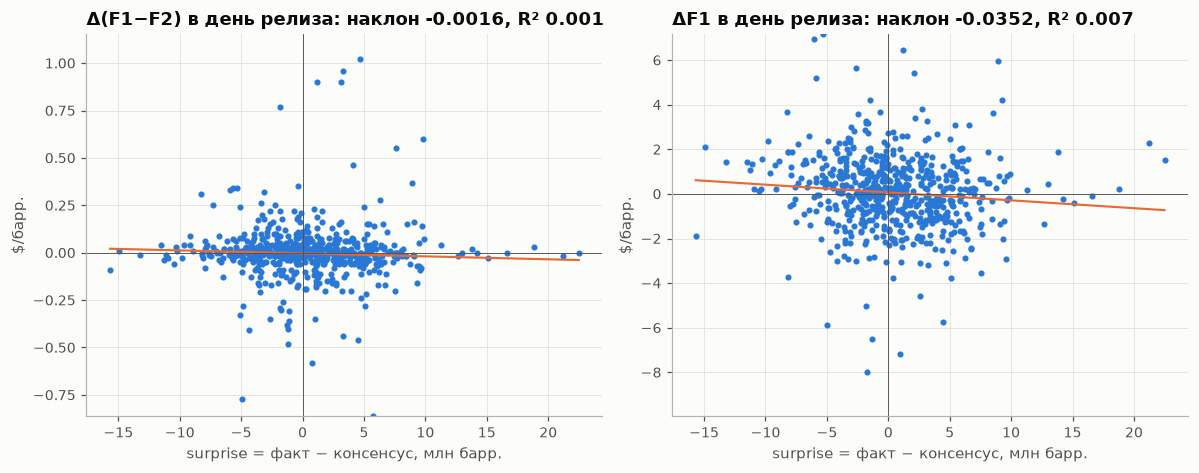

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, y, title, unit in [(axes[0], "ds12_0", "Δ(F1−F2) в день релиза", "$/барр."),
                           (axes[1], "dF1_0", "ΔF1 в день релиза", "$/барр.")]:
    d = ev[["surprise_mmbbl", y]].dropna()
    res = ols(d[y], d["surprise_mmbbl"])
    ax.scatter(d["surprise_mmbbl"], d[y], s=9, color=u.SERIES[0])
    gx = np.linspace(d["surprise_mmbbl"].min(), d["surprise_mmbbl"].max(), 50)
    ax.plot(gx, res.params["const"] + res.params["surprise_mmbbl"] * gx, color=u.SERIES[1], lw=1.4)
    ax.axhline(0, color=u.INK_MUTED, lw=0.6)
    ax.axvline(0, color=u.INK_MUTED, lw=0.6)
    lo, hi = d[y].quantile([0.003, 0.997])
    ax.set_ylim(lo - 0.1 * abs(lo), hi + 0.1 * abs(hi))
    ax.set_xlabel("surprise = факт − консенсус, млн барр.")
    ax.set_ylabel(unit)
    ax.set_title(f"{title}: наклон {res.params['surprise_mmbbl']:.4f}, R² {res.rsquared:.3f}")
fig.tight_layout()
plt.show()

                    N  surprise_med  ds12_mean  ds12_med  dF1_mean  dF1_med  z12_mean  z12_se  zF1_mean  zF1_se
q_surprise                                                                                                     
(-15.683, -3.35]  124        -5.025      0.011     0.005     0.468     0.55     0.059   0.106     0.323   0.097
(-3.35, -0.995]   123        -1.965      0.008     0.000     0.008     0.06     0.071   0.129     0.048   0.124
(-0.995, 1.124]   123         0.020      0.001     0.000    -0.000     0.16     0.054   0.089    -0.027   0.099
(1.124, 4.121]    123         2.661     -0.042    -0.010    -0.126    -0.25    -0.055   0.116    -0.069   0.099
(4.121, 22.491]   123         5.960      0.001    -0.010    -0.100    -0.11    -0.128   0.087    -0.198   0.100


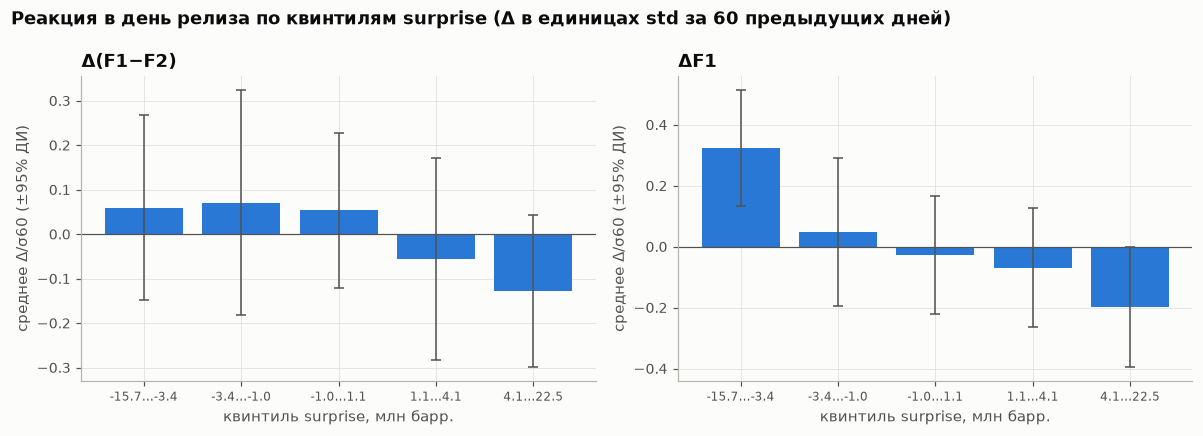

In [30]:
ev["q_surprise"] = pd.qcut(ev["surprise_mmbbl"], 5)
se_ = lambda s: s.std() / np.sqrt(s.count())  # noqa: E731
qtab = ev.groupby("q_surprise", observed=True).agg(
    N=("ds12_0", "size"), surprise_med=("surprise_mmbbl", "median"),
    ds12_mean=("ds12_0", "mean"), ds12_med=("ds12_0", "median"),
    dF1_mean=("dF1_0", "mean"), dF1_med=("dF1_0", "median"),
    z12_mean=("z12_0", "mean"), z12_se=("z12_0", se_), zF1_mean=("zF1_0", "mean"), zF1_se=("zF1_0", se_),
)
print(rnd(qtab, 3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xq = np.arange(len(qtab))
labels_q = [f"{iv.left:.1f}…{iv.right:.1f}" for iv in qtab.index]
for ax, m, se, title in [(axes[0], "z12_mean", "z12_se", "Δ(F1−F2)"), (axes[1], "zF1_mean", "zF1_se", "ΔF1")]:
    ax.bar(xq, qtab[m], color=u.SERIES[0])
    ax.errorbar(xq, qtab[m], yerr=1.96 * qtab[se], fmt="none", ecolor=u.INK_MUTED, lw=1, capsize=3)
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_xticks(xq, labels_q, fontsize=8)
    ax.set_xlabel("квинтиль surprise, млн барр.")
    ax.set_ylabel("среднее Δ/σ60 (±95% ДИ)")
    ax.set_title(title)
fig.suptitle("Реакция в день релиза по квинтилям surprise (Δ в единицах std за 60 предыдущих дней)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [31]:
# Дисперсия в дни релиза против прочих дней (и против нерелизных сред — контроль дня недели)
rel_set = set(ev["release_date"])
dd = bc[["dclean_f1_f2", "dF1_clean"]].copy()
dd["release"] = dd.index.isin(rel_set)
dd["wed"] = dd.index.day_of_week == 2
vrows = []
for col, name in [("dclean_f1_f2", "Δ(F1−F2)"), ("dF1_clean", "ΔF1")]:
    for sub, sname in [(dd, "все годы"), (dd[dd.index.year != 2020], "без 2020")]:
        a = sub.loc[sub["release"], col].dropna()
        b = sub.loc[~sub["release"], col].dropna()
        c = sub.loc[~sub["release"] & sub["wed"], col].dropna()
        vrows.append({"ряд": name, "выборка": sname, "std релиз": a.std(), "std прочие": b.std(),
                      "отн. дисперсий": a.var() / b.var(),
                      "p Левена (медиан.)": stats.levene(a, b, center="median").pvalue,
                      "std нерелизные среды": c.std(), "отн. к средам": a.var() / c.var(),
                      "среднее |Δ| релиз": a.abs().mean(), "среднее |Δ| прочие": b.abs().mean()})
print(rnd(pd.DataFrame(vrows).set_index(["ряд", "выборка"]), 4).to_string())
print("\nкрупнейшие |Δ(F1−F2)| в дни релиза:")
print(rnd(ev.loc[ev["ds12_0"].abs().nlargest(5).index, ["release_date", "ds12_0", "dF1_0", "surprise_mmbbl"]], 2)
      .to_string(index=False))
# Масштабно-независимое сравнение: |Δ/σ60| в дни релиза против прочих дней
zrows = []
for col, name in [("z_s12", "Δ(F1−F2)/σ60"), ("z_F1", "ΔF1/σ60")]:
    a = bc.loc[dd["release"], col].dropna().abs()
    b = bc.loc[~dd["release"], col].dropna().abs()
    c = bc.loc[~dd["release"] & dd["wed"], col].dropna().abs()
    zrows.append({"ряд": name, "сред. |z| релиз": a.mean(), "сред. |z| прочие": b.mean(),
                  "сред. |z| нерелизные среды": c.mean(), "медиана |z| релиз": a.median(),
                  "медиана |z| прочие": b.median(), "p Манна–Уитни (релиз vs прочие)": stats.mannwhitneyu(a, b).pvalue})
print()
print(rnd(pd.DataFrame(zrows).set_index("ряд"), 4).to_string())

                   std релиз  std прочие  отн. дисперсий  p Левена (медиан.)  std нерелизные среды  отн. к средам  среднее |Δ| релиз  среднее |Δ| прочие
ряд      выборка                                                                                                                                        
Δ(F1−F2) все годы     0.3232      0.2218          2.1236              0.9469                0.1366         5.5970             0.0930              0.0937
         без 2020     0.3311      0.2133          2.4091              0.8736                0.1410         5.5117             0.0934              0.0917
ΔF1      все годы     1.9266      1.6998          1.2846              0.0573                1.5803         1.4863             1.2741              1.1577
         без 2020     1.9649      1.7012          1.3341              0.0350                1.6033         1.5021             1.2985              1.1646

крупнейшие |Δ(F1−F2)| в дни релиза:
release_date  ds12_0  dF1_0  surprise_mmbbl
 

In [32]:
specs = {
    "все": ev.index == ev.index,
    "без дня ролла": ~ev["roll0"],
    "без окна ролла (2–6 дн. до эксп.)": ~ev["roll_window0"],
    "без 2020": ev["year"] != 2020,
    "без окна ролла и 2020": ~ev["roll_window0"] & (ev["year"] != 2020),
    "только среды": ev["dow"] == 2,
    "|surprise| ≤ 99-й перц.": ev["surprise_mmbbl"].abs() <= ev["surprise_mmbbl"].abs().quantile(0.99),
}
rob = []
for sname, m in specs.items():
    for y, yname in [("ds12_0", "Δ(F1−F2)"), ("dF1_0", "ΔF1")]:
        s = event_stats(ev[m], y)
        rob.append({"выборка": sname, "ряд": yname, **s[["N", "наклон $/млн барр.", "SE (HC1)", "p(наклон)",
                                                          "r Пирсон", "R²", "согласие знаков"]].to_dict()})
rob = pd.DataFrame(rob).set_index(["ряд", "выборка"]).sort_index(level=0, sort_remaining=False)
print(rnd(rob, 4).to_string())

# Устойчивость к выбросам и смене режимов: Δ/σ60 (МНК) и робастная регрессия Хьюбера на сырых Δ
alt = []
for y, yname in [("z12_0", "Δ(F1−F2)/σ60"), ("zF1_0", "ΔF1/σ60")]:
    for pname, a, b in [("все", 2015, 2026), ("2015–2019", 2015, 2019), ("2020–2026", 2020, 2026)]:
        m = (ev["year"] >= a) & (ev["year"] <= b)
        s = event_stats(ev[m], y)
        alt.append({"ряд": yname, "выборка": pname, "метод": "МНК, σ60 на 1 млн барр.",
                    **s[["N", "наклон $/млн барр.", "p(наклон)", "r Пирсон"]].rename({"наклон $/млн барр.": "наклон"}).to_dict()})
for y, yname in [("ds12_0", "Δ(F1−F2)"), ("dF1_0", "ΔF1")]:
    d = ev[[y, "surprise_mmbbl"]].dropna()
    h = sm.RLM(d[y], sm.add_constant(d["surprise_mmbbl"]), M=sm.robust.norms.HuberT()).fit()
    alt.append({"ряд": yname, "выборка": "все", "метод": "Хьюбер, $ на 1 млн барр.", "N": len(d),
                "наклон": h.params["surprise_mmbbl"], "p(наклон)": h.pvalues["surprise_mmbbl"], "r Пирсон": np.nan})
print()
print(rnd(pd.DataFrame(alt).set_index(["ряд", "выборка", "метод"]), 4).to_string())

                                                N  наклон $/млн барр.  SE (HC1)  p(наклон)  r Пирсон      R²  согласие знаков
ряд      выборка                                                                                                             
Δ(F1−F2) все                                616.0             -0.0016    0.0017     0.3484   -0.0229  0.0005           0.5515
         без дня ролла                      584.0             -0.0017    0.0018     0.3257   -0.0247  0.0006           0.5588
         без окна ролла (2–6 дн. до эксп.)  470.0             -0.0009    0.0022     0.6904   -0.0113  0.0001           0.5455
         без 2020                           563.0             -0.0024    0.0018     0.1784   -0.0335  0.0011           0.5530
         без окна ролла и 2020              430.0             -0.0014    0.0024     0.5534   -0.0176  0.0003           0.5443
         только среды                       526.0             -0.0018    0.0019     0.3563   -0.0245  0.0006          

                        N  наклон $/млн барр.  SE (HC1)  p(наклон)  r Пирсон      R²  согласие знаков   std Δ
ряд      период                                                                                              
Δ(F1−F2) 2015–2017  156.0             -0.0020    0.0017     0.2438   -0.0995  0.0099           0.5764  0.0806
         2018–2019  104.0             -0.0029    0.0013     0.0246   -0.2404  0.0578           0.5979  0.0569
         2020–2021  105.0              0.0029    0.0028     0.2999    0.0891  0.0079           0.5281  0.1684
         2022–2023  102.0              0.0013    0.0021     0.5407    0.0435  0.0019           0.4742  0.1664
         2024–2026  149.0             -0.0074    0.0068     0.2738   -0.0532  0.0028           0.5616  0.6211
ΔF1      2015–2017  156.0             -0.1057    0.0243     0.0000   -0.3129  0.0979           0.6154  1.3378
         2018–2019  104.0             -0.0814    0.0276     0.0032   -0.3033  0.0920           0.6442  1.2524
         2

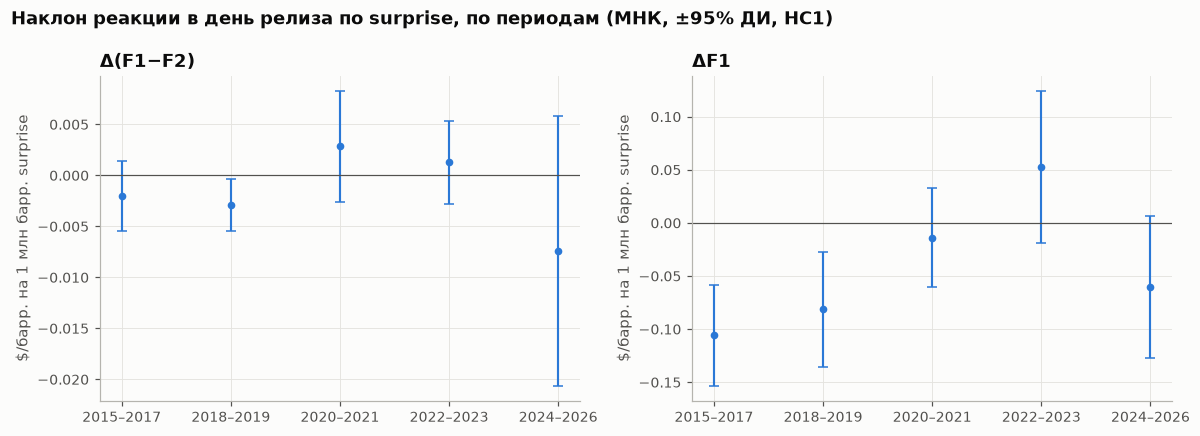

In [33]:
PERIODS = [("2015–2017", 2015, 2017), ("2018–2019", 2018, 2019), ("2020–2021", 2020, 2021),
           ("2022–2023", 2022, 2023), ("2024–2026", 2024, 2026)]
sp = []
for pname, a, b in PERIODS:
    m = (ev["year"] >= a) & (ev["year"] <= b)
    for y, yname in [("ds12_0", "Δ(F1−F2)"), ("dF1_0", "ΔF1")]:
        s = event_stats(ev[m], y)
        sp.append({"период": pname, "ряд": yname, **s[["N", "наклон $/млн барр.", "SE (HC1)", "p(наклон)",
                                                      "r Пирсон", "R²", "согласие знаков"]].to_dict(),
                   "std Δ": ev.loc[m, y].std()})
sp = pd.DataFrame(sp).set_index(["ряд", "период"]).sort_index(level=0, sort_remaining=False)
print(rnd(sp, 4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, yname in zip(axes, ["Δ(F1−F2)", "ΔF1"]):
    t = sp.loc[yname]
    xp = np.arange(len(t))
    ax.errorbar(xp, t["наклон $/млн барр."], yerr=1.96 * t["SE (HC1)"], fmt="o", color=u.SERIES[0],
                ecolor=u.SERIES[0], capsize=3)
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_xticks(xp, t.index)
    ax.set_ylabel("$/барр. на 1 млн барр. surprise")
    ax.set_title(yname)
fig.suptitle("Наклон реакции в день релиза по surprise, по периодам (МНК, ±95% ДИ, HC1)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

### 7.1. Разложение: (API − консенсус) против (факт − API), окна −1, 0, +1

День −1 — изменение от закрытия t−2 до закрытия t−1 (вторник для обычной недели): закрывается **до** выхода API,
поэтому значимый коэффициент при (API − консенсус) там означал бы утечку или ошибку тайминга. День +1 — продолжение или откат.

                        N  β API−конс.      SE       p  β факт−API     SE       p   R² оба  R² только API−конс.  R² только факт−API  R² surprise
ряд      окно                                                                                                                                   
Δ(F1−F2) день −1      616      -0.0001  0.0018  0.9586     -0.0042  0.0028  0.1359  0.0049               0.0004              0.0049       0.0011
         день релиза  616      -0.0016  0.0021  0.4636     -0.0016  0.0020  0.4402  0.0005               0.0003              0.0001       0.0005
         день +1      616       0.0052  0.0032  0.1098     -0.0023  0.0028  0.4034  0.0101               0.0092              0.0033       0.0023
ΔF1      день −1      616      -0.0230  0.0154  0.1336     -0.0133  0.0206  0.5197  0.0034               0.0028              0.0001       0.0031
         день релиза  616      -0.0425  0.0171  0.0130     -0.0202  0.0237  0.3931  0.0087               0.0075              0.000

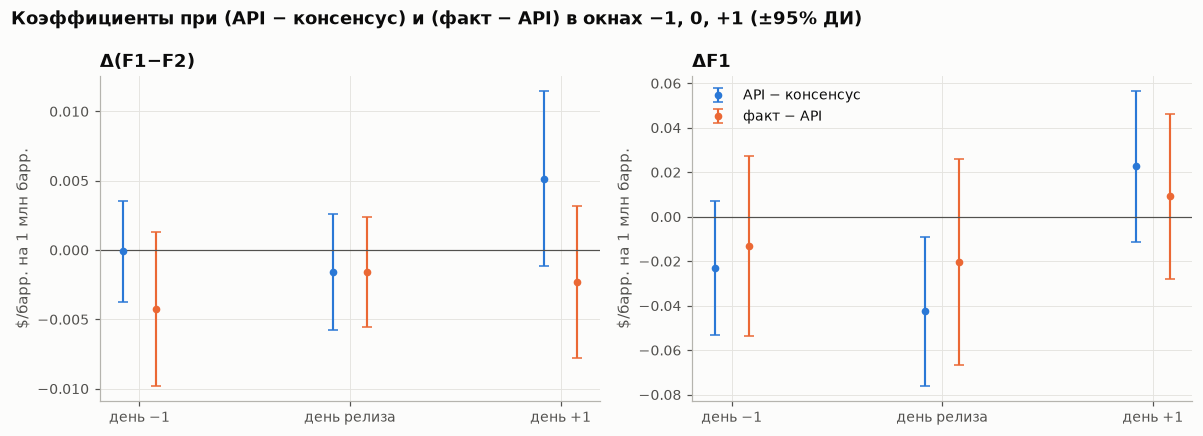

In [34]:
dec_rows, dec_models = [], {}
for tag, tname in [("m1", "день −1"), ("0", "день релиза"), ("p1", "день +1")]:
    for y, yname in [("ds12", "Δ(F1−F2)"), ("dF1", "ΔF1")]:
        d = ev[[f"{y}_{tag}", "api_cons", "act_api", "surprise_mmbbl"]].dropna()
        both = ols(d[f"{y}_{tag}"], d[["api_cons", "act_api"]])
        r2_api = ols(d[f"{y}_{tag}"], d["api_cons"]).rsquared
        r2_act = ols(d[f"{y}_{tag}"], d["act_api"]).rsquared
        r2_sur = ols(d[f"{y}_{tag}"], d["surprise_mmbbl"]).rsquared
        dec_models[(yname, tname)] = both
        dec_rows.append({"ряд": yname, "окно": tname, "N": len(d),
                         "β API−конс.": both.params["api_cons"], "SE": both.bse["api_cons"], "p": both.pvalues["api_cons"],
                         "β факт−API": both.params["act_api"], "SE ": both.bse["act_api"], "p ": both.pvalues["act_api"],
                         "R² оба": both.rsquared, "R² только API−конс.": r2_api, "R² только факт−API": r2_act,
                         "R² surprise": r2_sur})
dec = pd.DataFrame(dec_rows).set_index(["ряд", "окно"]).sort_index(level=0, sort_remaining=False)
print(rnd(dec, 4).to_string())
print(f"\nстд компонент: API−конс. {ev['api_cons'].std():.2f}, факт−API {ev['act_api'].std():.2f}, "
      f"surprise {ev['surprise_mmbbl'].std():.2f} млн барр.; corr(API−конс., факт−API) = {ev['api_cons'].corr(ev['act_api']):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, yname in zip(axes, ["Δ(F1−F2)", "ΔF1"]):
    t = dec.loc[yname]
    xp = np.arange(len(t))
    ax.errorbar(xp - 0.08, t["β API−конс."], yerr=1.96 * t["SE"], fmt="o", color=u.SERIES[0], capsize=3,
                label="API − консенсус")
    ax.errorbar(xp + 0.08, t["β факт−API"], yerr=1.96 * t["SE "], fmt="o", color=u.SERIES[1], capsize=3,
                label="факт − API")
    ax.axhline(0, color=u.INK_MUTED, lw=0.8)
    ax.set_xticks(xp, t.index)
    ax.set_ylabel("$/барр. на 1 млн барр.")
    ax.set_title(yname)
axes[1].legend(loc="upper left")
fig.suptitle("Коэффициенты при (API − консенсус) и (факт − API) в окнах −1, 0, +1 (±95% ДИ)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [35]:
# Добавочная информация: изменение запасов в Кушинге (без консенсуса) в день релиза
d = ev[["ds12_0", "surprise_mmbbl", "cushing_stocks_change_mmbbl"]].dropna()
m_c = ols(d["ds12_0"], d[["surprise_mmbbl", "cushing_stocks_change_mmbbl"]])
print(f"N = {len(d)}: Δ(F1−F2) ~ surprise + ΔКушинг")
print(rnd(pd.DataFrame({"β": m_c.params, "SE": m_c.bse, "p": m_c.pvalues}), 4).to_string())
print(f"R² = {m_c.rsquared:.4f} (только surprise: {ols(d['ds12_0'], d['surprise_mmbbl']).rsquared:.4f})")

N = 607: Δ(F1−F2) ~ surprise + ΔКушинг
                                  β      SE       p
const                       -0.0026  0.0130  0.8429
surprise_mmbbl              -0.0019  0.0017  0.2735
cushing_stocks_change_mmbbl  0.0062  0.0060  0.3005
R² = 0.0012 (только surprise: 0.0005)


**Вывод.** Ответ на ключевой вопрос по дневным закрытиям — **спрэд F1−F2 на surprise практически не реагирует**:
- 616 релизов (все — торговые дни Barchart; 526 в среду, 83 в четверг, 6 в пятницу, 1 в понедельник). Same-contract
  Δ(F1−F2) в день релиза: r = −0,023 (p = 0,57), Спирмен −0,078, наклон −0,0016 $ на 1 млн барр. (SE 0,0017, p = 0,35),
  R² = 0,0005. Знак верный и согласие знаков 55,2% (биномиальный p = 0,015), но эффект мизерный: 5 млн барр. surprise
  ≈ 0,8 цента при среднем |Δ| 9 центов. F1−F3 — то же (наклон −0,0033, p = 0,27). На наивном `delta_spread_f1_f2`
  наклон даже меняет знак (+0,0006).
- Робастность: без дней ролла, без окна ролла, без 2020, только среды, без 1% крупнейших |surprise| — наклон для спрэда
  в диапазоне −0,0024…−0,0009, все p ≥ 0,18; регрессия Хьюбера −0,0009 (p = 0,15). В единицах 60-дневной волатильности:
  −0,015 σ на 1 млн барр. (p = 0,074), причём −0,047 (p = 0,002, r = −0,20) в 2015–2019 и 0,000 (p = 0,97) в 2020–2026.
  По периодам в долларах значим только 2018–2019 (−0,0029, p = 0,025, r = −0,24).
- Цена F1 реагирует слабо, но устойчиво: наклон −0,035 $ на 1 млн барр. (p = 0,020; −0,07% на 1 млн барр.), r = −0,086,
  согласие знаков 58,0% (p = 0,0001); во всех спецификациях −0,034…−0,048 (p 0,003–0,04), Хьюбер −0,040 (p = 0,001).
  Крупнейшие draw (квинтиль surprise ≤ −3,35) дают в среднем +0,47 $ (медиана +0,55). Эффект сосредоточен в 2015–2019
  (−0,106 и −0,081 $, r ≈ −0,31), в 2020–2023 незначим (в 2022–2023 даже +0,053), в 2024–2026 −0,060 (p = 0,076).
- Дисперсия в дни релиза: std Δ(F1−F2) 0,323 против 0,222, но это целиком выбросы весны 2026 (2026-04-08: −6,91 $
  при surprise +2,4): среднее |Δ| одинаково (0,093 против 0,094, Левен p = 0,95), а нормированное |Δ/σ60| даже ниже
  (0,755 против 0,808, Манн–Уитни p = 0,14). Для F1 нормированное |Δ| выше на ~12% (0,869 против 0,778, p = 0,002).
- Разложение (тайминг): у F1 реакция в день релиза идёт через **API − консенсус** (β = −0,043, p = 0,013; R² 0,0075
  из 0,0087), а (факт − API) не добавляет ничего (β = −0,020, p = 0,39; R² 0,0000). Т.е. та часть surprise, что
  становится известна только в 10:30 ET в среду, на дневных закрытиях не видна; заметная часть «реакции на EIA» — это
  реакция на вечерний вторничный API. Для спрэда оба коэффициента ≈ −0,0016 и незначимы. В день −1 (закрытие до выхода API)
  значимых коэффициентов нет (для спрэда β при API − конс. = −0,0001, p = 0,96) — признаков утечки или сдвига дат нет;
  в день +1 продолжения или отката нет (все p ≥ 0,11). ΔКушинг из того же отчёта к surprise ничего не добавляет
  (β = +0,006, p = 0,30).

## 8. Сохранение очищенного дневного ряда

Разметка роллов и same-contract изменения нужны другим ноутбукам (07) и модели. Сохраняем их
в `eda/data/derived/curve_clean.parquet` (каталог в `.gitignore`, пересоздаётся этим ноутбуком).

In [36]:
derived = u.EDA_DIR / "data" / "derived"
derived.mkdir(parents=True, exist_ok=True)
clean_cols = ["wti_f1", "wti_f2", "wti_f3", "spread_f1_f2", "roll", "roll_window", "dclean_f1_f2", "dclean_f2_f3", "dclean_f1_f3", "dF1_clean"]
curve_clean = bc[clean_cols].rename_axis("trading_day").reset_index()
curve_clean.to_parquet(derived / "curve_clean.parquet", index=False)
print(f"{derived / 'curve_clean.parquet'}: {curve_clean.shape}, роллов {int(curve_clean['roll'].sum())}")

/home/lllyasch/Projects/oil-news-graph/eda/data/derived/curve_clean.parquet: (2981, 11), роллов 142


## Итоги

**Главные находки**
- Кривая WTI 2015–2026 проходит через резкие режимы: сплошное контанго 2015–2016, суперконтанго 2020 (F1−F2 до −7,29 $),
  устойчивая бэквордация 2021–2026 (2025–2026 — ≈100% дней) с экстремумом весной 2026 (F1−F2 +13,94 $, F1−F12 +41,57 $).
  F1−F2 > 0 в 53% дней всего периода.
- Barchart `{CL*n}` роллирует **за 2–8 торговых дней до экспирации** (мода 4), поэтому в ~25% дней «F1» — это второй контракт,
  а отрицательной цены 20.04.2020 в данных нет. Цены при этом совпадают с EIA до цента — различие только в конвенции ролла.
- `delta_spread_*` загрязнены роллами: в дни ролла (4,8% дней) |Δ(F1−F2)| в 2,5 раза больше обычного, это 14,7% суммы Δ².
  Same-contract Δ ((F1−F2)_t − (F2−F3)_{t−1} в день ролла) совпадает с EIA в 100% проверенных дней.
- Δ(F1−F2) имеет экстремальные хвосты (эксцесс 250) и сильную кластеризацию волатильности (60-дневное std от 0,02 до 1,33 $);
  нормировка на трейлинговое std снижает эксцесс до 13. Волатильность в 2,3 раза выше при бэквордации, чем при контанго.
- Уровень F1−F2 сильно связан с запасами в Кушинге (Спирмен −0,83), недельные изменения — слабо (−0,12).
- **Event study:** в день релиза EIA спрэд F1−F2 на surprise практически не реагирует (наклон −0,0016 $ на 1 млн барр.,
  p = 0,35, R² 0,0005; значимо лишь в 2015–2019 после нормировки на волатильность). Цена F1 реагирует слабо, но устойчиво
  (−0,035 $ на 1 млн барр., p = 0,02, R² 0,7%), в основном в 2015–2019, и эта реакция идёт через (API − консенсус),
  а не через (факт − API).

**Проблемы качества данных**
- `open_interest`: 100% NA (20 867 из 20 867 строк), во всех 7 nearby.
- `chart_volume_like_main`: одинаков во всех 7 nearby в 100% дней — не объём конкретного контракта; как признак ликвидности месяца непригоден.
- `change` = diff(close) nearby-ряда — в дни ролла смешивает контракты; идентификатора контракта в данных нет.
- `delta_spread_*` (8 колонок): содержат роллы (142 дня ролла: 109 точно по EIA + 33 по детектору с точностью ≈77% —
  янв.–февр. 2015 и апр. 2024 – окт. 2026); для F1−F6, F1−F12 same-contract-коррекция невозможна (нет F7/F13).
- Barchart: дубликатов, выходных и непраздничных пропусков нет (109 пропущенных будней — праздники CME).
- EIA фьючерсы: 18 строк на биржевые праздники 2018–2019 с ценами, скопированными с предыдущего дня (нулевые Δ);
  нет 12 торговых дней (3 Columbus, 3 Veterans, 5 пятниц после Thanksgiving, 2016-06-02); F1 держит истекающий контракт
  до экспирации (−37,63 $ 2020-04-20); `delta_spread_1_2` тоже загрязнён роллами (×2,7 в день после экспирации); ряд заканчивается 2024-04-05.
- 9 релизов без `cushing_stocks_change_mmbbl` (вне покрытия EIA weekly); 22 пятницы недели EIA — не торговые дни (берём четверг).

**Следствия для моделирования**
- Изменения спрэда/цены считать только same-contract (как `dclean_*` здесь), не брать `delta_spread_*` из файла; для дальних
  спрэдов исключать дни ролла. Для 2024–2026 разметка роллов приблизительна — лучше докачать посконтрактные ряды (CLxYY);
  до тех пор проверять результаты без `roll_window`.
- Явно зафиксировать, какой спрэд торгуется: в Barchart «F1−F2» между роллом и экспирацией — это пара (2-й − 3-й контракт).
- Из-за гетероскедастичности (смена режимов, весна 2026) нормировать Δ на трейлинговую волатильность и/или использовать
  робастные потери; признаки режима — знак и модуль F1−F2 накануне, уровень Кушинга (сильная связь уровней).
- Торговая гипотеза «surprise → дневное движение F1−F2» на закрытиях не подтверждается; сигнал есть в цене F1
  (2015–2019 сильнее). Часть реакции, приписываемой EIA, приходится на API (вторник 16:30 ET, после settlement), поэтому
  стратегия с входом после API должна оцениваться по (факт − API) — а для него эффект на дневных данных ≈ 0. Для проверки
  реакции на 10:30 ET нужны внутридневные цены.
- Anti-leakage: close Barchart — settlement (~14:30 ET) торгового дня; закрытие дня перед релизом не содержит ни API, ни EIA
  (в окне −1 реакции нет), поэтому его можно использовать как признак; API — только после 16:30 ET вторника (при переносе
  релиза EIA — на день позже, допущение). Недельные запасы известны лишь в день релиза.